# <u>Proyecto</u>: Análisis estadístico de series temporales ambientales de reservas de museos para la conservación preventiva sostenible de obras de arte

## 02b. Objetivo 1 — Selección y evaluación metodológica del detector de rareza temporal

Este notebook selecciona una referencia temporal parsimoniosa y compara una regla simple de rareza con una especificación más flexible. Retoma las decisiones sobre comparabilidad, interrupciones y periodicidad diaria documentadas en `02`, pero se concentra en la evaluación metodológica del detector, sin volver a caracterizar el ambiente de la reserva.

> **Pregunta rectora:** una vez retirados los comportamientos temporales previsibles de cada serie, ¿cuánta complejidad hace falta para identificar desviaciones temporales útiles e interpretables?

La cadena principal queda:

$$
X_t
\rightarrow
STL
\rightarrow
R_t
\rightarrow
\widehat R_t
\rightarrow
\hat\varepsilon_t
\rightarrow
z_t^{global}
\rightarrow
|z_t^{global}|>2.
$$

Como modelo ampliado se evalúa además:

$$
\hat\varepsilon_t
\rightarrow
\hat\sigma_t^{GARCH}
\rightarrow
z_t^{GARCH}
\rightarrow
p_t^{Student}.
$$

La comparación permite distinguir qué aporta modelar explícitamente la volatilidad condicional sin convertir esa complejidad en un requisito automático del detector. El producto final es `config/modelos_objetivo1.json`, que contiene la especificación seleccionada para su aplicación en el notebook `02`.

## Índice

1. Entradas metodológicas heredadas del notebook principal
2. Construcción de la referencia temporal: modelo de la media
3. ¿Una única escala de error alcanza?
4. De los diagnósticos de las innovaciones al modelo GARCH-t
5. Comparación de alternativas y selección del detector operativo
6. Exportación de la especificación seleccionada
7. Conclusión metodológica
8. Referencias

## 1. Entradas metodológicas heredadas del notebook principal

`02` estableció qué observaciones son comparables y qué estructura temporal debe respetarse. Aquí se reconstruyen sólo las entradas necesarias para seleccionar el detector: unidades de modelado, bloques continuos y el `remainder` de STL.

In [1]:
import warnings
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.special import gammaln
from statsmodels.tsa.seasonal import STL
from scipy import optimize
from scipy import stats
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# La búsqueda AR/MA/ARMA ajusta muchos candidatos; los que no convergen se
# descartan en la selección, así que sus avisos del optimizador no aportan.
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message='Non-stationary starting autoregressive parameters')
warnings.filterwarnings('ignore', message='Non-invertible starting MA parameters')

In [2]:
pd.options.display.max_columns = 35

In [3]:
df = pd.read_csv('../data/processed/sivori_horario_procesado.csv', sep=',', index_col='fecha', parse_dates=['fecha'])

In [4]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8905 entries, 2022-12-29 14:00:00 to 2024-01-04 14:00:00
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   H1 T (°C)              8872 non-null   float64
 1   H1 HRCal (%)           8872 non-null   float64
 2   H2 T (°C)              8903 non-null   float64
 3   H2 HRCal (%)           8903 non-null   float64
 4   H3 T (°C)              7823 non-null   float64
 5   H3 HRCal (%)           7823 non-null   float64
 6   H4 T (°C)              7603 non-null   float64
 7   H4 HRCal (%)           7603 non-null   float64
 8   SMN T (°C)             8905 non-null   float64
 9   SMN HR (%)             8905 non-null   float64
 10  SMN Prec. c/6 hs (mm)  8905 non-null   float64
 11  H1_disponible          8905 non-null   bool   
 12  H2_disponible          8905 non-null   bool   
 13  H3_disponible          8905 non-null   bool   
 14  H4_disponible          8905 non

In [5]:
HOBOS = ['H1', 'H2', 'H3', 'H4']
TEMP_INTERIOR = [f'{hobo} T (°C)' for hobo in HOBOS]
HR_INTERIOR = [f'{hobo} HRCal (%)' for hobo in HOBOS]
DISPONIBILIDAD_COLS = [f'{hobo}_disponible' for hobo in HOBOS]
TEMP_SMN = 'SMN T (°C)'
HR_SMN = 'SMN HR (%)'
TEMP_COLS = TEMP_INTERIOR + [TEMP_SMN]
HR_COLS = HR_INTERIOR + [HR_SMN]
COBERTURA_MINIMA_MENSUAL = 80
COLORES = {'H1': '#0072B2', 'H2': '#D55E00', 'H3': '#009E73', 'H4': '#CC79A7', 'SMN': '#7F7F7F'}

def color_de(col):
    return COLORES['SMN'] if col.startswith('SMN') else COLORES[col[:2]]

### 1.1 Unidades de modelado y bloques continuos

Se distinguen dos niveles de organización:

$$
\text{unidad de modelado}
\neq
\text{bloque continuo}.
$$

- Una **unidad de modelado** es una condición física de medición: H1, H3 y H4 tienen una cada uno; H2 se divide en H2-1 y H2-2 por la reubicación documentada.
- Un **bloque continuo** es un intervalo sin interrupciones, necesario cuando el cálculo depende de observaciones consecutivas.

Esta convención rige todo el notebook: **los parámetros se estiman por unidad** usando conjuntamente sus bloques válidos, mientras que **las operaciones que requieren adyacencia** (STL, rezagos ARMA, ARCH-LM y recursión GARCH) se calculan o reinician por bloque. Los huecos permanecen como faltantes y nunca generan adyacencias artificiales.

In [6]:
eventos = pd.read_csv('../data/metadata/eventos_conocidos.csv')

In [7]:
UMBRAL_HUECO_HORAS = 48
DIAS_MINIMOS_BLOQUE = 30

ventanas_descartadas = {
    fila['sensor']: (
        pd.Timestamp(fila['inicio']),
        pd.Timestamp(fila['fin']) + pd.Timedelta(days=1) - pd.Timedelta(hours=1),
    )
    for _, fila in eventos.iterrows()
    if fila['tipo'] == 'cambio_ubicacion'
}


def bloques_de(hobo):
    usable = df[f'{hobo}_disponible'].copy()

    if hobo in ventanas_descartadas:
        inicio_v, fin_v = ventanas_descartadas[hobo]
        usable.loc[inicio_v:fin_v] = False

    horas = df.index[usable]
    if len(horas) == 0:
        return []

    limite = pd.Timedelta(hours=UMBRAL_HUECO_HORAS)
    cortes = [(a, b) for a, b in zip(horas[:-1], horas[1:]) if b - a > limite]

    inicios = [horas[0]] + [b for _, b in cortes]
    fines = [a for a, _ in cortes] + [horas[-1]]

    bloques = []

    for i, (inicio, fin) in enumerate(zip(inicios, fines), start=1):
        horas_posibles = int((fin - inicio) / pd.Timedelta(hours=1)) + 1
        horas_disponibles = int(usable.loc[inicio:fin].sum())

        bloques.append({
            'sensor': hobo,
            'bloque': f'{hobo}-B{i}',
            'inicio': inicio,
            'fin': fin,
            'dias': (fin - inicio) / pd.Timedelta(days=1),
            'horas': horas_disponibles,
            'horas_posibles': horas_posibles,
            'cobertura_pct': 100 * horas_disponibles / horas_posibles,
        })

    return bloques


bloques_tecnicos = pd.DataFrame(
    [bloque for hobo in HOBOS for bloque in bloques_de(hobo)]
).set_index('bloque')

bloques_analizables = bloques_tecnicos.loc[
    bloques_tecnicos['dias'] >= DIAS_MINIMOS_BLOQUE
].copy()


def unidad_desde_bloque(fila):
    sensor = fila['sensor']

    if sensor != 'H2':
        return sensor

    inicio_v, fin_v = ventanas_descartadas['H2']

    if fila['fin'] < inicio_v:
        return 'H2-1'

    if fila['inicio'] > fin_v:
        return 'H2-2'

    return pd.NA


bloques_analizables['unidad'] = bloques_analizables.apply(
    unidad_desde_bloque,
    axis=1,
)

bloques_analizables = bloques_analizables.dropna(subset=['unidad'])


def resumir_unidades(bloques):
    filas = []

    for unidad, grupo in bloques.groupby('unidad', sort=False):
        horas = int(grupo['horas'].sum())
        horas_posibles = int(grupo['horas_posibles'].sum())

        filas.append({
            'unidad': unidad,
            'sensor': grupo['sensor'].iloc[0],
            'inicio': grupo['inicio'].min(),
            'fin': grupo['fin'].max(),
            'n_bloques': len(grupo),
            'horas': horas,
            'dias_observados': horas / 24,
            'cobertura_en_bloques_pct': (
                100 * horas / horas_posibles
                if horas_posibles
                else np.nan
            ),
        })

    return pd.DataFrame(filas).set_index('unidad')


unidades_analisis = resumir_unidades(bloques_analizables)

print('Bloques técnicos continuos:')
display(bloques_analizables.round({'dias': 2, 'cobertura_pct': 2}))

print('\nUnidades físicas/modeladas:')
display(unidades_analisis.round({'dias_observados': 2, 'cobertura_en_bloques_pct': 2}))

Bloques técnicos continuos:


,sensor,inicio,fin,dias,horas,horas_posibles,cobertura_pct,unidad
bloque,,,,,,,,
H1-B1,H1,2022-12-29 14:00:00,2024-01-04 14:00:00,371.00,8872,8905,99.63,H1
H2-B1,H2,2022-12-29 14:00:00,2023-04-07 23:00:00,99.38,2385,2386,99.96,H2-1
H2-B2,H2,2023-04-15 00:00:00,2024-01-04 14:00:00,264.58,6350,6351,99.98,H2-2
H3-B1,H3,2022-12-29 14:00:00,2023-09-05 17:00:00,250.12,5971,6004,99.45,H3
H3-B2,H3,2023-10-19 11:00:00,2024-01-04 14:00:00,77.12,1852,1852,100.00,H3
H4-B1,H4,2022-12-29 14:00:00,2023-07-01 12:00:00,183.92,4413,4415,99.95,H4
H4-B2,H4,2023-08-24 17:00:00,2024-01-04 14:00:00,132.88,3190,3190,100.00,H4



Unidades físicas/modeladas:


,sensor,inicio,fin,n_bloques,horas,dias_observados,cobertura_en_bloques_pct
unidad,,,,,,,
H1,H1,2022-12-29 14:00:00,2024-01-04 14:00:00,1,8872,369.67,99.63
H2-1,H2,2022-12-29 14:00:00,2023-04-07 23:00:00,1,2385,99.38,99.96
H2-2,H2,2023-04-15 00:00:00,2024-01-04 14:00:00,1,6350,264.58,99.98
H3,H3,2022-12-29 14:00:00,2024-01-04 14:00:00,2,7823,325.96,99.58
H4,H4,2022-12-29 14:00:00,2024-01-04 14:00:00,2,7603,316.79,99.97


In [8]:
COLUMNA_T = dict(zip(HOBOS, TEMP_INTERIOR))
COLUMNA_HR = dict(zip(HOBOS, HR_INTERIOR))


def serie_unidad(unidad, columnas):
    fila = unidades_analisis.loc[unidad]
    sensor = fila['sensor']

    return df.loc[
        fila['inicio']:fila['fin'],
        columnas[sensor],
    ]


def series_por_unidad(columnas):
    return {
        unidad: serie_unidad(unidad, columnas)
        for unidad in unidades_analisis.index
    }


series_t = series_por_unidad(COLUMNA_T)
series_hr = series_por_unidad(COLUMNA_HR)

print(f"{len(series_t)} unidades de T: {', '.join(series_t)}")
print(f"{len(series_hr)} unidades de HR: {', '.join(series_hr)}")

5 unidades de T: H1, H2-1, H2-2, H3, H4
5 unidades de HR: H1, H2-1, H2-2, H3, H4


### 1.2 Señal que entra al modelo de media: `remainder` de STL

El detector no se aplica directamente sobre T o HR observadas. Primero se retiran la evolución lenta y la componente diaria de 24 h:

$$
X_t = T_t + S_t + R_t,
\qquad
R_t = X_t-T_t-S_t.
$$

$R_t$ es el objeto que entra al modelo AR/MA/ARMA. STL se ajusta por bloque continuo suficientemente largo, sin imputar huecos.

In [9]:
def bloques_continuos(serie, min_obs=1):
    """Separa una serie en bloques con paso horario exacto, sin imputar."""
    s = serie.dropna().sort_index().astype(float)
    if s.empty:
        return []
    grupos = s.index.to_series().diff().ne(pd.Timedelta(hours=1)).cumsum()
    return [bloque.copy() for _, bloque in s.groupby(grupos) if len(bloque) >= min_obs]

def bloque_continuo_mas_largo(serie, min_obs=1):
    """Bloque continuo más largo para diagnósticos que exigen continuidad."""
    bloques = bloques_continuos(serie, min_obs=min_obs)
    if not bloques:
        return pd.Series(dtype=float, name=getattr(serie, 'name', None))
    return max(bloques, key=len)

In [10]:
PERIODO_STL_H = 24
MIN_CICLOS_STL = 7
MIN_OBS_STL = PERIODO_STL_H * MIN_CICLOS_STL

def descomponer_stl(serie, periodo=PERIODO_STL_H):
    """
    Descompone TODOS los bloques horarios continuos suficientemente largos.

    Cada bloque se ajusta de forma independiente. No se imputan faltantes y
    ningún componente se estima atravesando un hueco.

    Devuelve un DataFrame concatenado con:
    - observado
    - tendencia
    - estacional
    - resto
    - bloque_id
    """
    bloques = bloques_continuos(serie, min_obs=MIN_OBS_STL)
    partes = []
    for bloque_id, s in enumerate(bloques, start=1):
        ajuste = STL(s, period=periodo, robust=True).fit()
        partes.append(pd.DataFrame({
            'observado': s,
            'tendencia': ajuste.trend,
            'estacional': ajuste.seasonal,
            'resto': ajuste.resid,
            'bloque_id': bloque_id,
        }))
    if not partes:
        return pd.DataFrame(columns=['observado', 'tendencia', 'estacional', 'resto', 'bloque_id'])
    return pd.concat(partes).sort_index()
descomp_temp = {unidad: descomponer_stl(serie) for unidad, serie in series_t.items()}
descomp_hr = {unidad: descomponer_stl(serie) for unidad, serie in series_hr.items()}
residuos_temp = {unidad: resultado['resto'] for unidad, resultado in descomp_temp.items() if not resultado.empty}
residuos_hr = {unidad: resultado['resto'] for unidad, resultado in descomp_hr.items() if not resultado.empty}

def cobertura_stl(series_originales, descomposiciones):
    filas = []
    for unidad, serie in series_originales.items():
        n_original = int(serie.notna().sum())
        n_stl = int(descomposiciones.get(unidad, pd.DataFrame()).shape[0])
        filas.append({
            'unidad': unidad,
            'n_observado_unidad': n_original,
            'n_usado_STL': n_stl,
            'pct_observado_usado_STL': 100 * n_stl / n_original if n_original > 0 else np.nan,
        })
    return pd.DataFrame(filas).set_index('unidad')
print(f'STL calculada para {len(residuos_temp)} unidades de temperatura y {len(residuos_hr)} unidades de humedad relativa.')
print('\nCobertura efectiva de STL - temperatura:')
display(cobertura_stl(series_t, descomp_temp).round(2))
print('\nCobertura efectiva de STL - HR:')
display(cobertura_stl(series_hr, descomp_hr).round(2))

STL calculada para 5 unidades de temperatura y 5 unidades de humedad relativa.

Cobertura efectiva de STL - temperatura:


,n_observado_unidad,n_usado_STL,pct_observado_usado_STL
unidad,,,
H1,8872,8872,100.0
H2-1,2385,2385,100.0
H2-2,6350,6350,100.0
H3,7823,7823,100.0
H4,7603,7603,100.0



Cobertura efectiva de STL - HR:


,n_observado_unidad,n_usado_STL,pct_observado_usado_STL
unidad,,,
H1,8872,8872,100.0
H2-1,2385,2385,100.0
H2-2,6350,6350,100.0
H3,7823,7823,100.0
H4,7603,7603,100.0


In [11]:
def acf_pairwise(serie, max_lag, paso=pd.Timedelta(hours=1)):
    """ACF usando sólo pares separados exactamente por el rezago calendario."""
    s = serie.dropna().sort_index().astype(float)
    filas = []
    for lag in range(max_lag + 1):
        if lag == 0:
            n = len(s)
            correlacion = 1.0 if n > 0 else np.nan
        else:
            rezagada = s.copy()
            rezagada.index = rezagada.index + lag * paso
            pares = pd.concat(
                [s.rename('actual'), rezagada.rename('rezagada')],
                axis=1,
                sort=False,
            ).dropna()
            n = len(pares)
            correlacion = pares['actual'].corr(pares['rezagada']) if n >= 2 else np.nan
        filas.append({'lag': lag, 'correlacion': correlacion, 'n_pares': n})
    return pd.DataFrame(filas).set_index('lag')
LAG_MAX_RESTO = 72
acf_resid_temp = {
    unidad: acf_pairwise(serie, LAG_MAX_RESTO)
    for unidad, serie in residuos_temp.items()
}
acf_resid_hr = {
    unidad: acf_pairwise(serie, LAG_MAX_RESTO)
    for unidad, serie in residuos_hr.items()
}

In [12]:
def redondear_numericas(tabla, decimales=3):
    """
    Redondea valores numéricos en DataFrame o Series.

    - DataFrame: redondea solo columnas numéricas.
    - Series: redondea solo los elementos numéricos y conserva
      strings, fechas u otros objetos sin modificarlos.
    """
    resultado = tabla.copy()
    if isinstance(resultado, pd.DataFrame):
        columnas_numericas = resultado.select_dtypes(include='number').columns
        resultado[columnas_numericas] = resultado[columnas_numericas].round(decimales)
        return resultado
    if isinstance(resultado, pd.Series):
        return resultado.map(lambda x: round(
            x,
            decimales,
        ) if isinstance(x, (int, float, np.integer, np.floating)) and (not isinstance(x, bool)) else x)
    raise TypeError('redondear_numericas espera un pandas DataFrame o Series.')

## 2. Construcción de la referencia temporal: modelo de la media

> **Pregunta rectora:** dado el pasado reciente del `remainder`, ¿qué valor era razonable esperar en la hora actual?

Después de retirar la evolución lenta y la componente diaria mediante STL, se ajusta un modelo ARMA de bajo orden para representar la dependencia temporal que puede permanecer en el `remainder`.

A partir de los modelos ajustados se obtienen las innovaciones, definidas como la diferencia entre el remanente observado y su media condicional estimada:

$$
\hat{\varepsilon}_t=R_t-\widehat{R}_t.
$$

Las innovaciones representan la variación que no logra anticiparse mediante la estructura temporal modelada y constituyen la base para la identificación de anomalías.

### 2.1 Familia candidata

Todas las unidades pasan por la misma familia y las mismas reglas:

- `trend="n"`, porque STL deja el `remainder` centrado;
- órdenes cortos AR/MA/ARMA, definidos antes de ver el ganador;
- convergencia, estacionariedad de la parte AR e invertibilidad de la parte MA;
- BIC como criterio principal y parsimonia cuando varios candidatos quedan dentro de $\Delta BIC\le2$.

El rezago 24 **no forma parte de la familia operativa**. La componente diaria ya fue separada mediante STL y agregar automáticamente un AR(24) por una asociación residual a 24 h puede introducir una complejidad difícil de interpretar.

Se conserva, sin embargo, un control de sensibilidad en las series donde la búsqueda exploratoria previa había favorecido una especificación con lag 24. La decisión final se toma por su efecto sobre el diagnóstico y, sobre todo, sobre el catálogo de eventos (sección 5.1).

In [13]:
BASE_ARMA = [(0, 0), (1, 0), (2, 0), (3, 0), (0, 1), (0, 2), (0, 3), (1, 1), (2, 1), (1, 2)]
DELTA_BIC_EQUIVALENCIA = 2.0
MAXITER_MODELO_MEDIA = 200
MARGEN_RAICES = 1.001

def regularizar_horario_para_modelo(serie):
    """
    Reindexa a una grilla horaria completa.

    Los huecos permanecen como NaN para no crear falsas adyacencias.
    """
    s = serie.dropna().sort_index().astype(float)
    if s.empty:
        return s
    return s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='h'))

def lags_ar_modelo(p, ar24):
    lags = list(range(1, p + 1))
    if ar24:
        lags.append(24)
    return lags

def etiqueta_modelo_media(p, q, ar24):
    partes = []
    if p > 0:
        partes.append(f'AR({p})')
    if q > 0:
        partes.append(f'MA({q})')
    if ar24:
        partes.append('AR(24)')
    return '+'.join(partes) if partes else 'WN'

def minimo_modulo_raices(raices):
    raices = np.asarray(raices)
    if len(raices) == 0:
        return np.nan
    return float(np.min(np.abs(raices)))
CANDIDATOS_MODELO_MEDIA = [{'p': p, 'q': q, 'ar24': False} for p, q in BASE_ARMA]

def ajustar_candidatos_modelo_media(serie):
    """
    Ajusta la misma familia prefijada de candidatos a una serie.

    El remainder de STL se modela SIN constante (`trend="n"`).

    Sólo compiten por BIC candidatos:
      - convergentes;
      - con BIC finito;
      - estacionarios en la parte AR;
      - invertibles en la parte MA;
      - con raíces fuera del círculo unitario por MARGEN_RAICES.
    """
    y = regularizar_horario_para_modelo(serie)
    filas = []
    ajustes = {}
    for candidato in CANDIDATOS_MODELO_MEDIA:
        p = candidato['p']
        q = candidato['q']
        ar24 = candidato['ar24']
        ar_lags = lags_ar_modelo(p, ar24)
        nombre = etiqueta_modelo_media(p, q, ar24)
        p_spec = ar_lags if ar_lags else 0
        try:
            ajuste = SARIMAX(
                y,
                order=(p_spec, 0, q),
                seasonal_order=(0, 0, 0, 0),
                trend='n',
                enforce_stationarity=True,
                enforce_invertibility=True,
                simple_differencing=False,
            ).fit(
                disp=False,
                maxiter=MAXITER_MODELO_MEDIA,
            )
            convergio = bool(getattr(ajuste, 'mle_retvals', {}).get('converged', True))
            min_raiz_ar = minimo_modulo_raices(ajuste.arroots)
            min_raiz_ma = minimo_modulo_raices(ajuste.maroots)
            estacionario = True if np.isnan(min_raiz_ar) else min_raiz_ar > MARGEN_RAICES
            invertible = True if np.isnan(min_raiz_ma) else min_raiz_ma > MARGEN_RAICES
            bic_finito = np.isfinite(float(ajuste.bic))
            valido = convergio and estacionario and invertible and bic_finito
            n_ar = len(ar_lags)
            fila = {
                'modelo': nombre,
                'p_corto': p,
                'q': q,
                'ar24': ar24,
                'lags_ar': ','.join(map(str, ar_lags)) if ar_lags else '',
                'n_ar': n_ar,
                'complejidad_dinamica': n_ar + q,
                'aic': float(ajuste.aic),
                'bic': float(ajuste.bic),
                'hqic': float(ajuste.hqic),
                'n_parametros': len(ajuste.params),
                'n_observado': int(y.notna().sum()),
                'convergio': convergio,
                'min_mod_raiz_AR': min_raiz_ar,
                'min_mod_raiz_MA': min_raiz_ma,
                'estacionario': estacionario,
                'invertible': invertible,
                'valido': valido,
                'error': '',
            }
            filas.append(fila)
            if valido:
                ajustes[p, q, ar24] = ajuste
        except Exception as exc:
            filas.append({
                'modelo': nombre,
                'p_corto': p,
                'q': q,
                'ar24': ar24,
                'lags_ar': ','.join(map(str, ar_lags)) if ar_lags else '',
                'n_ar': len(ar_lags),
                'complejidad_dinamica': len(ar_lags) + q,
                'aic': np.nan,
                'bic': np.nan,
                'hqic': np.nan,
                'n_parametros': np.nan,
                'n_observado': int(y.notna().sum()),
                'convergio': False,
                'min_mod_raiz_AR': np.nan,
                'min_mod_raiz_MA': np.nan,
                'estacionario': False,
                'invertible': False,
                'valido': False,
                'error': str(exc),
            })
    tabla = pd.DataFrame(filas)
    validos = tabla['valido'] & tabla['bic'].notna()
    if not validos.any():
        raise RuntimeError('Ningún candidato convergente, estacionario e invertible quedó disponible.')
    tabla_validos = tabla.loc[validos].copy().sort_values('bic')
    bic_minimo = float(tabla_validos['bic'].min())
    tabla['delta_bic'] = tabla['bic'] - bic_minimo
    equivalentes = tabla.loc[validos & (tabla['delta_bic'] <= DELTA_BIC_EQUIVALENCIA)].copy()
    equivalentes['ar24_orden'] = equivalentes['ar24'].astype(int)
    elegido = equivalentes.sort_values([
        'n_parametros',
        'ar24_orden',
        'complejidad_dinamica',
        'bic',
        'p_corto',
        'q',
    ]).iloc[0]
    p_sel = int(elegido['p_corto'])
    q_sel = int(elegido['q'])
    ar24_sel = bool(elegido['ar24'])
    tabla['seleccionado'] = (tabla['p_corto'] == p_sel) & (tabla['q'] == q_sel) & (tabla['ar24'] == ar24_sel) & tabla['valido']
    mejor_bic = tabla_validos.iloc[0]
    return (
        tabla,
        ajustes[p_sel, q_sel, ar24_sel],
        {
            'p': p_sel,
            'q': q_sel,
            'ar24': ar24_sel,
            'modelo': elegido['modelo'],
            'lags_ar': elegido['lags_ar'],
            'n_ar': int(elegido['n_ar']),
            'aic': float(elegido['aic']),
            'bic': float(elegido['bic']),
            'hqic': float(elegido['hqic']),
            'n_parametros': int(elegido['n_parametros']),
            'n_observado': int(elegido['n_observado']),
            'min_mod_raiz_AR': float(elegido['min_mod_raiz_AR']) if pd.notna(elegido['min_mod_raiz_AR']) else np.nan,
            'min_mod_raiz_MA': float(elegido['min_mod_raiz_MA']) if pd.notna(elegido['min_mod_raiz_MA']) else np.nan,
            'bic_minimo': bic_minimo,
            'modelo_bic_minimo': mejor_bic['modelo'],
            'delta_bic_seleccionado': float(elegido['bic'] - bic_minimo),
            'delta_bic_segundo': float(tabla_validos.iloc[1]['bic'] - tabla_validos.iloc[0]['bic']) if len(tabla_validos) > 1 else np.nan,
            'n_equivalentes_delta2': int(len(equivalentes)),
            'regla_parsimonia_aplicada': bool(elegido['bic'] - bic_minimo > 1e-09),
        },
    )

def seleccionar_modelos_coleccion(residuos, variable):
    modelos = {}
    innovaciones = {}
    detalle = []
    seleccion = []

    for unidad, serie in residuos.items():
        print(f'Ajustando {variable} - {unidad}')

        tabla, ajuste, resumen = ajustar_candidatos_modelo_media(serie)
        y = regularizar_horario_para_modelo(serie)

        innovacion = pd.Series(
            np.asarray(ajuste.resid, dtype=float),
            index=y.index,
            name='innovacion_modelo_media',
        )
        innovacion.loc[y.isna()] = np.nan

        burn = int(getattr(ajuste, 'loglikelihood_burn', 0))
        if burn > 0:
            innovacion.iloc[:burn] = np.nan

        innovacion = innovacion.reindex(serie.dropna().sort_index().index)

        modelos[unidad] = ajuste
        innovaciones[unidad] = innovacion

        tabla['variable'] = variable
        tabla['unidad'] = unidad
        detalle.append(tabla)

        seleccion.append({
            'variable': variable,
            'unidad': unidad,
            **resumen,
        })

        raiz_msg = (
            f"| min raíz AR={resumen['min_mod_raiz_AR']:.4f}"
            if pd.notna(resumen['min_mod_raiz_AR'])
            else '| sin parte AR'
        )

        print(
            '  ->',
            resumen['modelo'],
            f"| BIC={resumen['bic']:.2f}",
            raiz_msg,
            f"| ΔBIC={resumen['delta_bic_seleccionado']:.2f}",
        )

    return (
        modelos,
        innovaciones,
        pd.concat(detalle, ignore_index=True),
        pd.DataFrame(seleccion),
    )


modelos_media_temp, innovaciones_temp, candidatos_media_temp, seleccion_media_temp = seleccionar_modelos_coleccion(
    residuos_temp,
    'T',
)

modelos_media_hr, innovaciones_hr, candidatos_media_hr, seleccion_media_hr = seleccionar_modelos_coleccion(
    residuos_hr,
    'HR',
)

tabla_seleccion_media = (
    pd.concat(
        [seleccion_media_temp, seleccion_media_hr],
        ignore_index=True,
    )
    .set_index(['variable', 'unidad'])
    .sort_index()
)

print('Modelos temporales seleccionados por unidad:')
display(
    tabla_seleccion_media[[
        'modelo',
        'lags_ar',
        'bic',
        'min_mod_raiz_AR',
        'min_mod_raiz_MA',
        'delta_bic_seleccionado',
        'n_equivalentes_delta2',
    ]].round(4)
)

Ajustando T - H1
  -> AR(1)+MA(2) | BIC=-12901.58 | min raíz AR=1.1454 | ΔBIC=0.00
Ajustando T - H2-1
  -> AR(1)+MA(1) | BIC=-3437.27 | min raíz AR=1.2328 | ΔBIC=0.00
Ajustando T - H2-2
  -> AR(1)+MA(2) | BIC=-4976.29 | min raíz AR=1.1095 | ΔBIC=0.00
Ajustando T - H3
  -> AR(1)+MA(1) | BIC=-11598.61 | min raíz AR=1.1988 | ΔBIC=0.00
Ajustando T - H4
  -> AR(2)+MA(1) | BIC=-23329.91 | min raíz AR=1.1378 | ΔBIC=0.00
Ajustando HR - H1
  -> AR(2)+MA(1) | BIC=22379.44 | min raíz AR=1.2090 | ΔBIC=0.00
Ajustando HR - H2-1
  -> AR(2)+MA(1) | BIC=5727.58 | min raíz AR=1.1132 | ΔBIC=0.00
Ajustando HR - H2-2
  -> AR(2)+MA(1) | BIC=17252.25 | min raíz AR=1.2176 | ΔBIC=0.00
Ajustando HR - H3
  -> AR(2)+MA(1) | BIC=20835.28 | min raíz AR=1.0759 | ΔBIC=0.00
Ajustando HR - H4
  -> AR(2)+MA(1) | BIC=19650.00 | min raíz AR=1.0147 | ΔBIC=0.00
Modelos temporales seleccionados por unidad:


modelo lags_ar         bic  min_mod_raiz_AR  \
variable unidad                                                     
HR       H1      AR(2)+MA(1)     1,2  22379.4441           1.2090   
         H2-1    AR(2)+MA(1)     1,2   5727.5752           1.1132   
         H2-2    AR(2)+MA(1)     1,2  17252.2516           1.2176   
         H3      AR(2)+MA(1)     1,2  20835.2848           1.0759   
         H4      AR(2)+MA(1)     1,2  19650.0009           1.0147   
T        H1      AR(1)+MA(2)       1 -12901.5826           1.1454   
         H2-1    AR(1)+MA(1)       1  -3437.2703           1.2328   
         H2-2    AR(1)+MA(2)       1  -4976.2934           1.1095   
         H3      AR(1)+MA(1)       1 -11598.6105           1.1988   
         H4      AR(2)+MA(1)     1,2 -23329.9087           1.1378   

                 min_mod_raiz_MA  delta_bic_seleccionado  \
variable unidad                                            
HR       H1               1.5017                     0.0   
         H2-1             1.0926                     0.0   
         H2-2             1.6225                     0.0   
         H3               1.0314                     0.0   
         H4               1.0272                     0.0   
T        H1               2.5684                     0.0   
         H2-1             7.6992                     0.0   
         H2-2             3.5795                     0.0   
         H3               6.6498                     0.0   
         H4               1.3082                     0.0   

                 n_equivalentes_delta2  
variable unidad                         
HR       H1                          1  
         H2-1                        1  
         H2-2                        1  
         H3                          1  
         H4                          1  
T        H1                          2  
         H2-1                        3  
         H2-2                        1  
         H3                          2  
         H4                          1

### 2.2 Resultado de la selección

La búsqueda se restringe a modelos ARMA de bajo orden y permite seleccionar una especificación por variable y unidad de análisis. El criterio de selección prioriza una representación parsimoniosa de la dependencia temporal del `remainder`, con el propósito de obtener innovaciones que posteriormente puedan analizarse en términos de su dispersión y distribución.

In [14]:
resumen_regla_parsimonia = pd.Series({
    'n_modelos_seleccionados': len(tabla_seleccion_media),
    'n_con_regla_parsimonia': int(tabla_seleccion_media['regla_parsimonia_aplicada'].sum()),
    'delta_bic_seleccionado_max': tabla_seleccion_media['delta_bic_seleccionado'].max(),
    'delta_bic_seleccionado_mediana': tabla_seleccion_media['delta_bic_seleccionado'].median(),
})

print('Resumen de la selección ARMA corta:')
display(resumen_regla_parsimonia.round(4))

Resumen de la selección ARMA corta:


n_modelos_seleccionados           10.0
n_con_regla_parsimonia             0.0
delta_bic_seleccionado_max         0.0
delta_bic_seleccionado_mediana     0.0
dtype: float64

En T se seleccionan tres especificaciones de bajo orden: ARMA(1,2), ARMA(1,1) y ARMA(2,1). En HR, las cinco unidades seleccionan ARMA(2,1). En todos los casos, las raíces de los polinomios AR y MA permanecen fuera del círculo unitario, cumpliendo las condiciones de estacionariedad e invertibilidad, respectivamente.

### 2.3 ¿La referencia elegida retiró suficiente dependencia de la media?

Una vez seleccionado el ARMA corto se revisa la dependencia residual, con especial atención al rezago de 24 h.

La pregunta no es exigir autocorrelación exactamente nula. Se busca comprobar si la referencia de bajo orden deja una estructura suficientemente acotada para trabajar con innovaciones, y si la asociación diaria residual justifica realmente agregar un término específico a 24 h.

In [15]:
LAG_MAX_INNOVACION = 48
acf_innov_temp = {unidad: acf_pairwise(serie, LAG_MAX_INNOVACION) for unidad, serie in innovaciones_temp.items()}
acf_innov_hr = {unidad: acf_pairwise(serie, LAG_MAX_INNOVACION) for unidad, serie in innovaciones_hr.items()}

def resumen_acf_seleccionados(acf_resto, acf_innov, variable):
    filas = []
    for unidad in acf_innov:
        for lag in [1, 2, 3, 6, 12, 24, 48]:
            if lag not in acf_innov[unidad].index or lag not in acf_resto[unidad].index:
                continue
            antes = acf_resto[unidad].loc[lag, 'correlacion']
            despues = acf_innov[unidad].loc[lag, 'correlacion']
            filas.append({
                'variable': variable,
                'unidad': unidad,
                'lag_h': lag,
                'acf_remainder': antes,
                'acf_innovacion': despues,
                'reduccion_abs': abs(antes) - abs(despues),
            })
    return pd.DataFrame(filas).set_index(['variable', 'unidad', 'lag_h'])
diagnostico_modelos_seleccionados = pd.concat([
    resumen_acf_seleccionados(acf_resid_temp, acf_innov_temp, 'T'),
    resumen_acf_seleccionados(acf_resid_hr, acf_innov_hr, 'HR'),
])
display(diagnostico_modelos_seleccionados.xs(24, level='lag_h').round(4))

acf_remainder  acf_innovacion  reduccion_abs
variable unidad                                              
T        H1            -0.1371         -0.1206         0.0165
         H2-1          -0.0913         -0.0658         0.0256
         H2-2          -0.1030          0.0476         0.0554
         H3            -0.0710         -0.0314         0.0395
         H4            -0.0621          0.2111        -0.1490
HR       H1            -0.0233          0.1615        -0.1382
         H2-1          -0.0705          0.1857        -0.1152
         H2-2          -0.0465          0.2216        -0.1751
         H3            -0.0944          0.2435        -0.1491
         H4            -0.0260          0.1928        -0.1668

La asociación a 24 h no desaparece de forma uniforme con el ARMA corto. En algunas series se reduce, como T-H1, T-H2-1 y T-H3; en otras aumenta o cambia de signo, especialmente en HR y T-H4. Esto es coherente con que el modelo corto esté retirando memoria local y no haya sido diseñado específicamente para reproducir una estructura diaria residual.

Por eso la ACF a 24 h se utiliza como diagnóstico y no como regla automática para agregar un término AR(24).

In [16]:
ESPECIFICACIONES_LAG24_SENSIBILIDAD = {
    ('T', 'H1'): {'p': 3, 'q': 0},
    ('T', 'H3'): {'p': 1, 'q': 1},
    ('HR', 'H4'): {'p': 2, 'q': 1},
}


def ajustar_modelo_media_fijo(serie, p, q, ar24=False):
    y = regularizar_horario_para_modelo(serie)
    ar_lags = lags_ar_modelo(p, ar24)
    p_spec = ar_lags if ar_lags else 0

    ajuste = SARIMAX(
        y,
        order=(p_spec, 0, q),
        seasonal_order=(0, 0, 0, 0),
        trend='n',
        enforce_stationarity=True,
        enforce_invertibility=True,
        simple_differencing=False,
    ).fit(disp=False, maxiter=MAXITER_MODELO_MEDIA)

    innovacion = pd.Series(
        np.asarray(ajuste.resid, dtype=float),
        index=y.index,
        name='innovacion_modelo_media',
    )
    innovacion.loc[y.isna()] = np.nan

    burn = int(getattr(ajuste, 'loglikelihood_burn', 0))
    if burn > 0:
        innovacion.iloc[:burn] = np.nan

    return ajuste, innovacion.reindex(serie.dropna().sort_index().index)


modelos_lag24_sens = {'T': {}, 'HR': {}}
innovaciones_lag24_sens = {'T': {}, 'HR': {}}
filas_lag24 = []

for (variable, unidad), especificacion in ESPECIFICACIONES_LAG24_SENSIBILIDAD.items():
    residuos = residuos_temp if variable == 'T' else residuos_hr
    innovaciones_cortas = innovaciones_temp if variable == 'T' else innovaciones_hr

    ajuste_lag24, innovacion_lag24 = ajustar_modelo_media_fijo(
        residuos[unidad],
        p=especificacion['p'],
        q=especificacion['q'],
        ar24=True,
    )

    modelos_lag24_sens[variable][unidad] = ajuste_lag24
    innovaciones_lag24_sens[variable][unidad] = innovacion_lag24

    acf_corta = acf_pairwise(innovaciones_cortas[unidad], 24)
    acf_lag24 = acf_pairwise(innovacion_lag24, 24)

    filas_lag24.append({
        'variable': variable,
        'unidad': unidad,
        'modelo_corto': tabla_seleccion_media.loc[(variable, unidad), 'modelo'],
        'modelo_lag24': etiqueta_modelo_media(
            especificacion['p'],
            especificacion['q'],
            True,
        ),
        'bic_corto': tabla_seleccion_media.loc[(variable, unidad), 'bic'],
        'bic_lag24': float(ajuste_lag24.bic),
        'delta_bic_corto_menos_lag24': (
            tabla_seleccion_media.loc[(variable, unidad), 'bic']
            - float(ajuste_lag24.bic)
        ),
        'acf24_corto': acf_corta.loc[24, 'correlacion'],
        'acf24_lag24': acf_lag24.loc[24, 'correlacion'],
    })


sensibilidad_media_lag24 = (
    pd.DataFrame(filas_lag24)
    .set_index(['variable', 'unidad'])
    .sort_index()
)

print('Control de sensibilidad del modelo de media:')
display(sensibilidad_media_lag24.round(4))

Control de sensibilidad del modelo de media:


modelo_corto        modelo_lag24   bic_corto   bic_lag24  \
variable unidad                                                            
HR       H4      AR(2)+MA(1)  AR(2)+MA(1)+AR(24)  19650.0009  19559.8103   
T        H1      AR(1)+MA(2)        AR(3)+AR(24) -12901.5826 -12952.4789   
         H3      AR(1)+MA(1)  AR(1)+MA(1)+AR(24) -11598.6105 -11601.9024   

                 delta_bic_corto_menos_lag24  acf24_corto  acf24_lag24  
variable unidad                                                         
HR       H4                          90.1906       0.1928       0.1103  
T        H1                          50.8963      -0.1206      -0.0643  
         H3                           3.2918      -0.0314      -0.0098

### 2.4 Decisión sobre la media condicional

La sensibilidad confirma que el rezago 24 mejora el ajuste en algunos casos, pero cambia muy poco los eventos que finalmente se identificarían.

- En **T-H1**, agregar lag 24 mejora el BIC en 50,9 puntos y reduce $|\rho_{24}|$ de 0,121 a 0,064.
- En **HR-H4**, mejora el BIC en 90,2 puntos y reduce $\rho_{24}$ de 0,193 a 0,110.
- En **T-H3**, la mejora es pequeña: $\Delta BIC=3,29$ y $\rho_{24}$ pasa de −0,031 a −0,010.

La comparación posterior del catálogo (sección 5.1) muestra que el ARMA corto recupera entre **96,5 % y 100 %** de los eventos detectados con las versiones que incorporan lag 24. Por eso la mejora de ajuste no se traduce en una diferencia sustantiva para el objetivo aplicado.

Se fija entonces como referencia operativa:

$$
\boxed{
R_{j,t}
\rightarrow
\widehat M_j^{ARMA}
\rightarrow
\hat\varepsilon_{j,t}
}
$$

con **ARMA corto sin lag 24**. La asociación residual diaria se conserva como limitación diagnóstica, no como término automático del modelo.

## 3. ¿Una única escala de error alcanza?

Una primera alternativa para identificar desviaciones temporales consiste en estandarizar las innovaciones utilizando una única escala residual por unidad de modelado:

$$
z_t^{global}=\frac{\hat{\varepsilon}_t-\bar{\varepsilon}}{s_\varepsilon}.
$$

Esta referencia permite expresar cada innovación en términos de la dispersión global de los errores. Sin embargo, no distingue entre períodos con mayor o menor variabilidad.

Para examinar sus limitaciones, se estudian tres aspectos:

1. La evolución temporal de la dispersión de las innovaciones.
2. La dependencia temporal de su magnitud, mediante $|\hat{\varepsilon}_t|$ y $\hat{\varepsilon}_t^2$.
3. La distribución de las innovaciones, especialmente su comportamiento en las colas.

Estos diagnósticos permiten evaluar si resulta pertinente incorporar una escala condicional y una distribución más flexible antes de comparar las alternativas de detección.

### 3.1 La dispersión cambia en el tiempo

El desvío estándar móvil y los resúmenes mensuales permiten evaluar si una misma escala residual resulta representativa durante todo el registro.

Si la dispersión cambia de manera apreciable, una desviación estándar global mezcla períodos tranquilos con períodos más variables. Esto no invalida una regla global como herramienta descriptiva, pero sí motiva evaluar una especificación con escala condicional.

In [17]:
VENTANA_ESCALA_INNOV_DIAS = 14
VENTANA_ESCALA_INNOV_H = 24 * VENTANA_ESCALA_INNOV_DIAS
MIN_OBS_ESCALA_INNOV = VENTANA_ESCALA_INNOV_H // 2

def escala_convencional_movil(serie):
    """
    Diagnóstico de escala todavía no robusto:
    media móvil y desvío estándar móvil.
    """
    s = serie.dropna().astype(float)
    ventana = f'{VENTANA_ESCALA_INNOV_H}h'
    media_movil = s.rolling(ventana, min_periods=MIN_OBS_ESCALA_INNOV, center=True).mean()
    sd_movil = s.rolling(ventana, min_periods=MIN_OBS_ESCALA_INNOV, center=True).std(ddof=1)
    return pd.DataFrame({'innovacion': s, 'media_movil': media_movil, 'sd_movil': sd_movil})
diagnostico_escala_temp = {unidad: escala_convencional_movil(serie) for unidad, serie in innovaciones_temp.items()}
diagnostico_escala_hr = {unidad: escala_convencional_movil(serie) for unidad, serie in innovaciones_hr.items()}

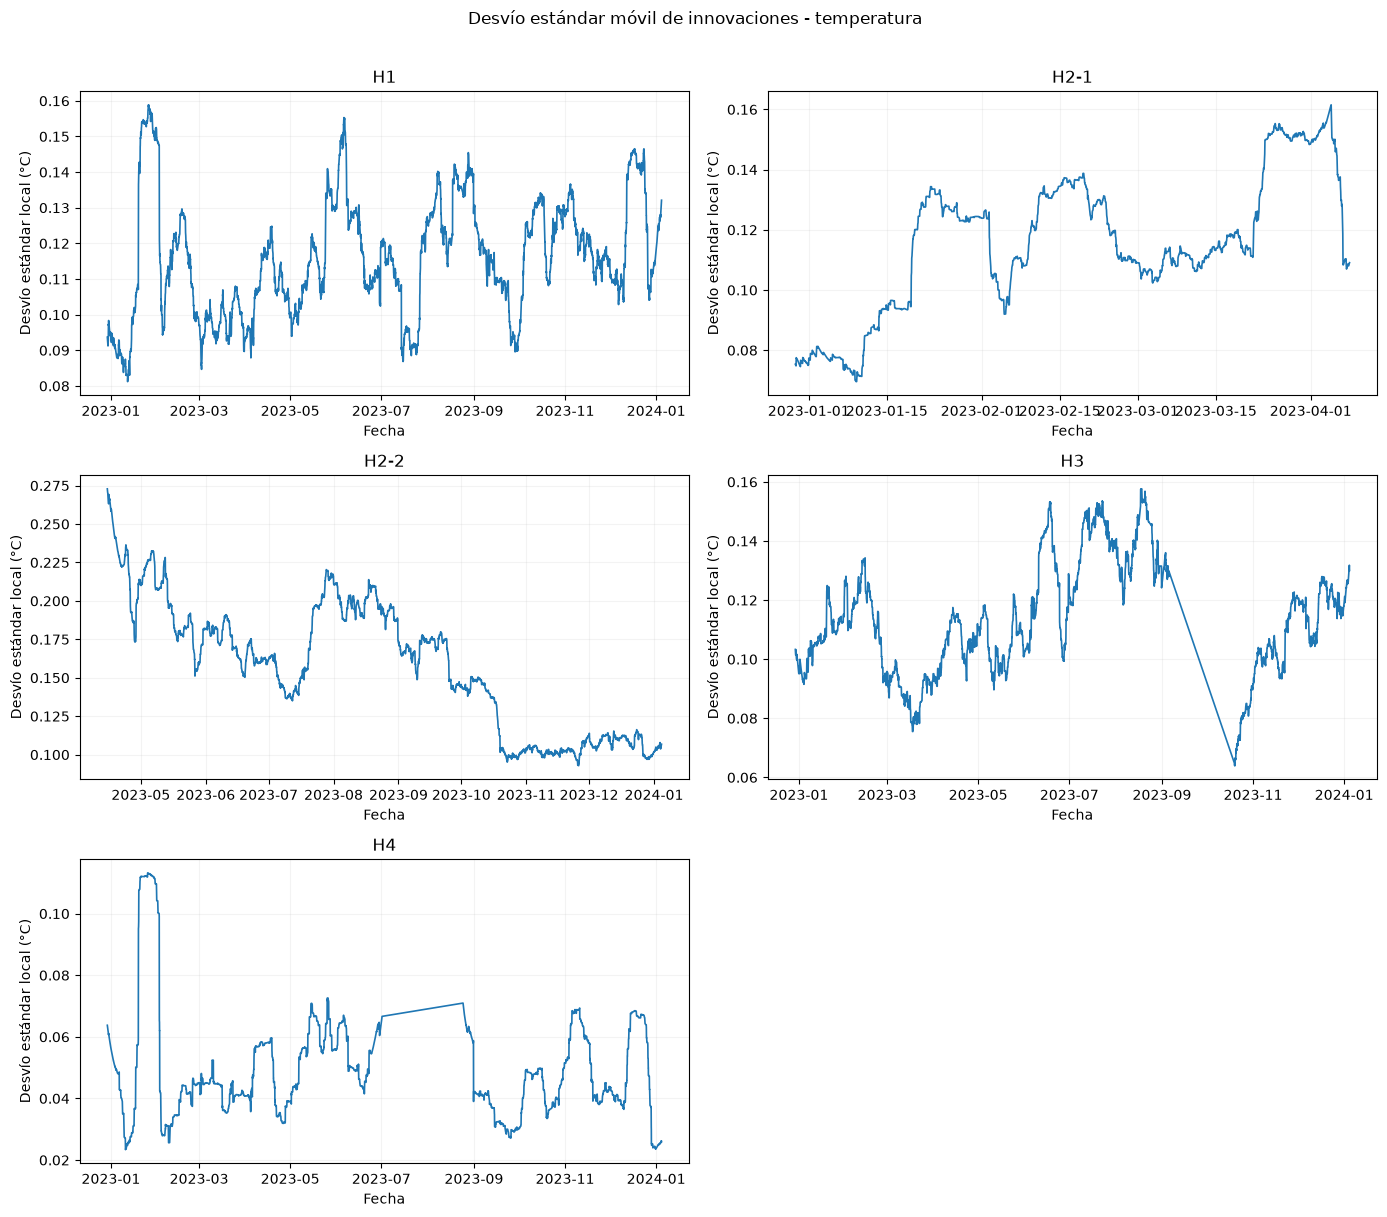

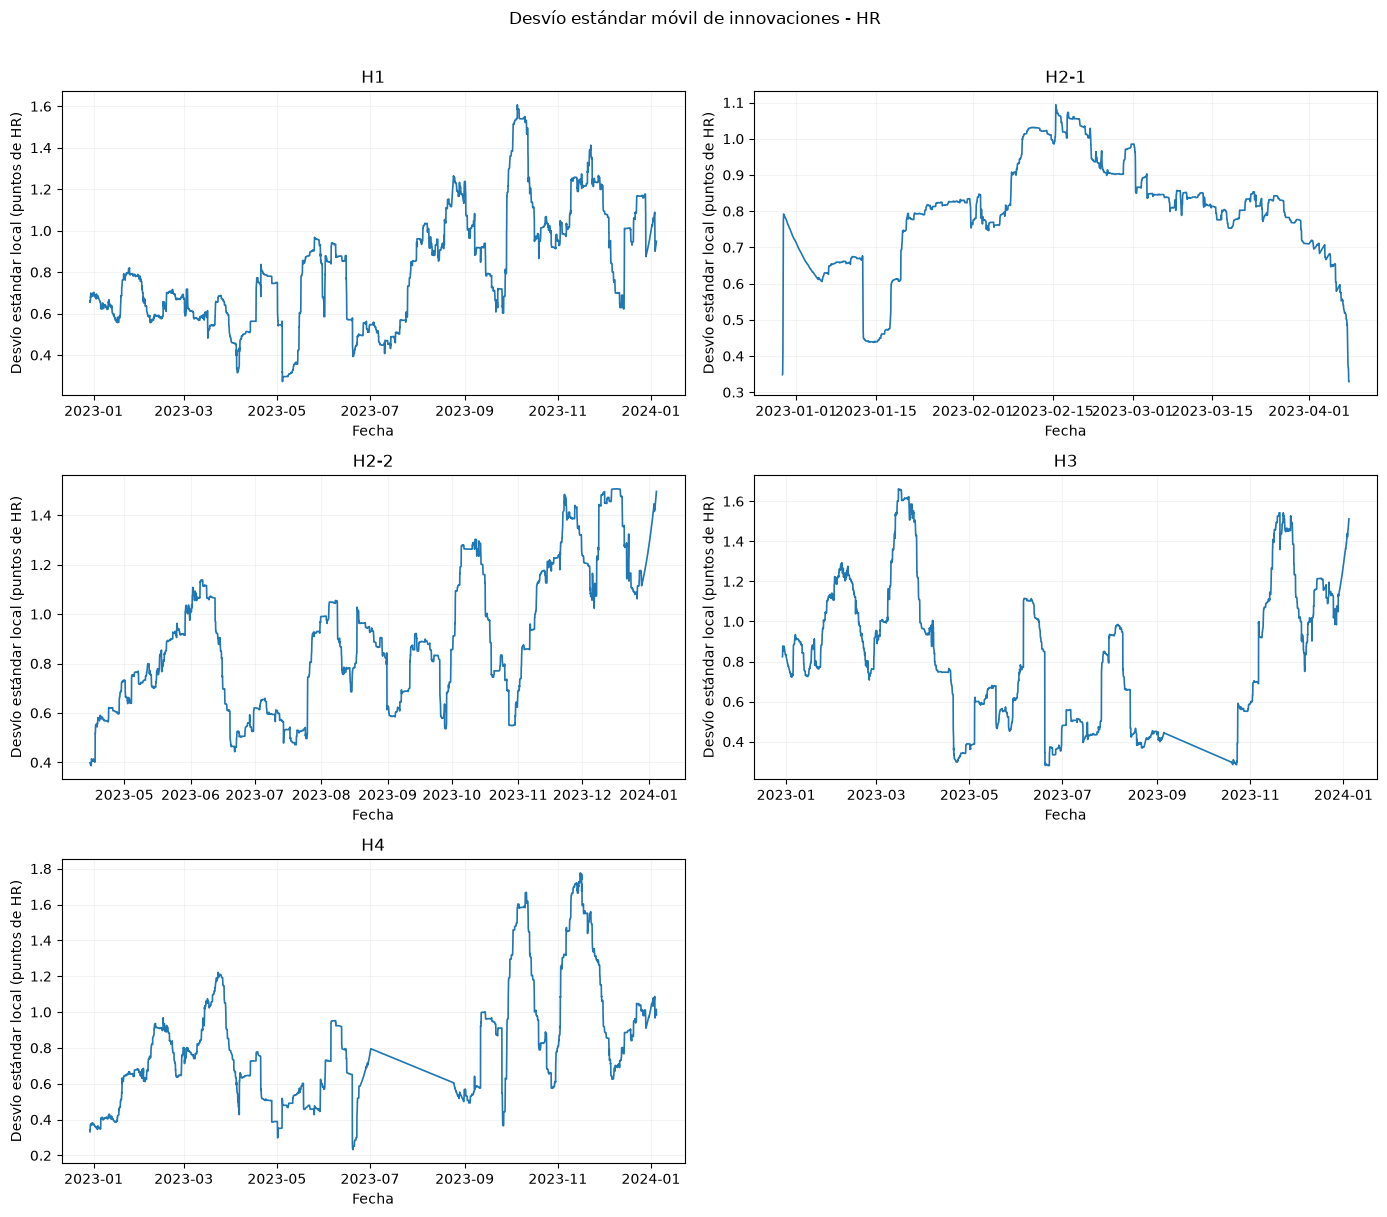

In [18]:
def graficar_escala_innovaciones(diagnosticos, titulo, ylabel):
    unidades = list(diagnosticos.keys())
    ncols = 2
    nrows = int(np.ceil(len(unidades) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.0 * nrows), sharex=False)
    axes = np.atleast_1d(axes).ravel()
    for ax, unidad in zip(axes, unidades):
        r = diagnosticos[unidad]
        ax.plot(r.index, r['sd_movil'], linewidth=1.2)
        ax.set_title(unidad)
        ax.set_xlabel('Fecha')
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.15)
    for ax in axes[len(unidades):]:
        ax.remove()
    fig.suptitle(titulo, y=1.01)
    plt.tight_layout()
    plt.show()
graficar_escala_innovaciones(
    diagnostico_escala_temp,
    'Desvío estándar móvil de innovaciones - temperatura',
    'Desvío estándar local (°C)',
)
graficar_escala_innovaciones(
    diagnostico_escala_hr,
    'Desvío estándar móvil de innovaciones - HR',
    'Desvío estándar local (puntos de HR)',
)

In [19]:
def resumen_mensual_innovaciones(innovaciones):
    filas = []
    for unidad, serie in innovaciones.items():
        s = serie.dropna().astype(float)
        grupos = s.groupby(s.index.to_period('M'))
        for mes, valores in grupos:
            filas.append({
                'unidad': unidad,
                'mes': str(mes),
                'n': len(valores),
                'media_innovacion': valores.mean(),
                'sd_innovacion': valores.std(ddof=1),
                'p95_abs_innovacion': valores.abs().quantile(0.95),
            })
    return pd.DataFrame(filas).set_index(['unidad', 'mes'])
mensual_innov_temp = resumen_mensual_innovaciones(innovaciones_temp)
mensual_innov_hr = resumen_mensual_innovaciones(innovaciones_hr)
print('Resumen mensual de innovaciones - temperatura:')
display(redondear_numericas(mensual_innov_temp, 3))
print('Resumen mensual de innovaciones - HR:')
display(redondear_numericas(mensual_innov_hr, 3))

Resumen mensual de innovaciones - temperatura:


n  media_innovacion  sd_innovacion  p95_abs_innovacion
unidad mes                                                              
H1     2022-12   58             0.007          0.091               0.185
       2023-01  744            -0.003          0.122               0.258
       2023-02  672             0.003          0.114               0.266
       2023-03  743             0.003          0.101               0.261
       2023-04  720             0.002          0.108               0.258
       2023-05  744            -0.002          0.118               0.279
       2023-06  719             0.002          0.119               0.254
       2023-07  744             0.001          0.102               0.241
       2023-08  713             0.000          0.134               0.274
       2023-09  720             0.002          0.113               0.263
       2023-10  744             0.004          0.122               0.270
       2023-11  720             0.002          0.119               0.265
       2023-12  744             0.002          0.125               0.267
       2024-01   87             0.003          0.138               0.298
H2-1   2022-12   58             0.015          0.086               0.149
       2023-01  744            -0.003          0.104               0.275
       2023-02  672             0.003          0.121               0.288
       2023-03  743             0.005          0.129               0.288
       2023-04  168            -0.007          0.109               0.257
H2-2   2023-04  384            -0.002          0.234               0.510
       2023-05  744            -0.007          0.194               0.402
       2023-06  719             0.001          0.172               0.358
       2023-07  744             0.003          0.167               0.325
       2023-08  744             0.001          0.199               0.447
       2023-09  720             0.004          0.167               0.358
       2023-10  744             0.001          0.125               0.269
       2023-11  720            -0.001          0.101               0.258
       2023-12  744             0.001          0.112               0.267
       2024-01   87             0.000          0.068               0.173
H3     2022-12   58             0.014          0.106               0.267
       2023-01  744            -0.003          0.108               0.274
       2023-02  672             0.001          0.115               0.271
       2023-03  743             0.002          0.090               0.258
       2023-04  720             0.002          0.104               0.278
       2023-05  744             0.003          0.110               0.287
       2023-06  719             0.001          0.121               0.265
       2023-07  744             0.002          0.140               0.296
       2023-08  713            -0.003          0.136               0.303
       2023-09  114            -0.039          0.152               0.378
       2023-10  301             0.002          0.080               0.222
       2023-11  720             0.001          0.105               0.256
       2023-12  744             0.003          0.116               0.284
       2024-01   87            -0.000          0.145               0.366
H4     2022-12   58            -0.001          0.070               0.087
       2023-01  744             0.000          0.080               0.116
       2023-02  672             0.001          0.037               0.068
       2023-03  743             0.002          0.045               0.081
       2023-04  720             0.001          0.046               0.084
       2023-05  744             0.000          0.058               0.106
       2023-06  719             0.001          0.057               0.114
       2023-07   13            -0.001          0.012               0.026
       2023-08  175             0.001          0.070               0.080
       2023-09  720             0.000          0.036               0.071
   

Resumen mensual de innovaciones - HR:


n  media_innovacion  sd_innovacion  p95_abs_innovacion
unidad mes                                                              
H1     2022-12   58            -0.013          0.735               1.861
       2023-01  744            -0.005          0.713               1.494
       2023-02  672             0.008          0.639               1.417
       2023-03  743             0.023          0.607               1.269
       2023-04  720             0.028          0.640               0.834
       2023-05  744             0.005          0.646               1.157
       2023-06  719            -0.003          0.729               1.161
       2023-07  744             0.008          0.534               1.048
       2023-08  713            -0.016          1.110               2.500
       2023-09  720             0.000          0.800               1.625
       2023-10  744            -0.041          1.265               3.016
       2023-11  720            -0.054          1.216               2.630
       2023-12  744             0.018          0.939               1.908
       2024-01   87            -0.029          0.699               1.972
H2-1   2022-12   58             0.018          0.295               0.615
       2023-01  744            -0.051          0.718               1.349
       2023-02  672             0.031          0.922               2.036
       2023-03  743            -0.017          0.856               2.109
       2023-04  168             0.014          0.329               0.591
H2-2   2023-04  384             0.020          0.601               1.229
       2023-05  744             0.048          0.799               1.854
       2023-06  719             0.001          0.846               1.602
       2023-07  744            -0.009          0.550               1.028
       2023-08  744            -0.007          0.967               1.933
       2023-09  720             0.002          0.740               1.273
       2023-10  744            -0.038          1.019               2.085
       2023-11  720            -0.055          1.230               3.207
       2023-12  744            -0.003          1.263               2.204
       2024-01   87            -0.034          1.099               2.560
H3     2022-12   58            -0.133          0.633               1.565
       2023-01  744            -0.069          0.901               1.999
       2023-02  672            -0.003          1.035               2.442
       2023-03  743            -0.054          1.385               3.336
       2023-04  720             0.018          0.624               1.235
       2023-05  744            -0.007          0.560               1.035
       2023-06  719            -0.037          0.798               1.146
       2023-07  744            -0.036          0.475               0.940
       2023-08  713            -0.018          0.723               1.226
       2023-09  114             0.097          0.387               0.841
       2023-10  301             0.002          0.570               0.728
       2023-11  720            -0.066          1.235               2.746
       2023-12  744            -0.012          1.040               2.006
       2024-01   87             0.045          1.636               4.063
H4     2022-12   58             0.031          0.313               0.632
       2023-01  744            -0.009          0.531               1.134
       2023-02  672             0.023          0.797               1.624
       2023-03  743             0.004          0.990               2.577
       2023-04  720             0.012          0.563               0.757
       2023-05  744            -0.010          0.452               0.935
       2023-06  719            -0.015          0.766               1.086
       2023-07   13            -0.026          0.108               0.177
       2023-08  175            -0.026          0.598               1.063
       2023-09  720            -0.005          0.742               0.854
   

La dispersión de las innovaciones cambia de manera visible durante el año. El efecto es moderado en varias series de T, pero muy marcado en HR y en algunas unidades particulares. En HR, por ejemplo, el desvío mensual va de 0,53 a 1,27 en H1, de 0,39 a 1,64 en H3 y de 0,11 a 1,46 en H4.

Una misma innovación absoluta, por lo tanto, puede ocurrir en un período normalmente estable o en otro mucho más variable. Esta heterogeneidad es el principal argumento para probar una escala condicional.

### 3.2 La magnitud de los errores también tiene memoria

Una vez retirada la media condicional, interesa saber si los errores grandes tienden a agruparse.

Se inspecciona la dependencia de

$$
|\hat\varepsilon_t|
\qquad\text{y}\qquad
\hat\varepsilon_t^2.
$$

La persistencia de estas transformaciones indicaría que la **intensidad** del error también tiene dinámica propia, aunque la innovación en nivel ya esté centrada.

In [20]:
LAG_MAX_MAGNITUD = 48

def acf_transformada(innovaciones, transformacion, max_lag=LAG_MAX_MAGNITUD):
    resultados = {}
    for unidad, serie in innovaciones.items():
        s = serie.dropna().astype(float)
        if transformacion == 'abs':
            y = s.abs()
        elif transformacion == 'sq':
            y = s ** 2
        else:
            y = s
        resultados[unidad] = acf_pairwise(y, max_lag)
    return resultados
acf_abs_temp = acf_transformada(innovaciones_temp, 'abs')
acf_sq_temp = acf_transformada(innovaciones_temp, 'sq')
acf_abs_hr = acf_transformada(innovaciones_hr, 'abs')
acf_sq_hr = acf_transformada(innovaciones_hr, 'sq')

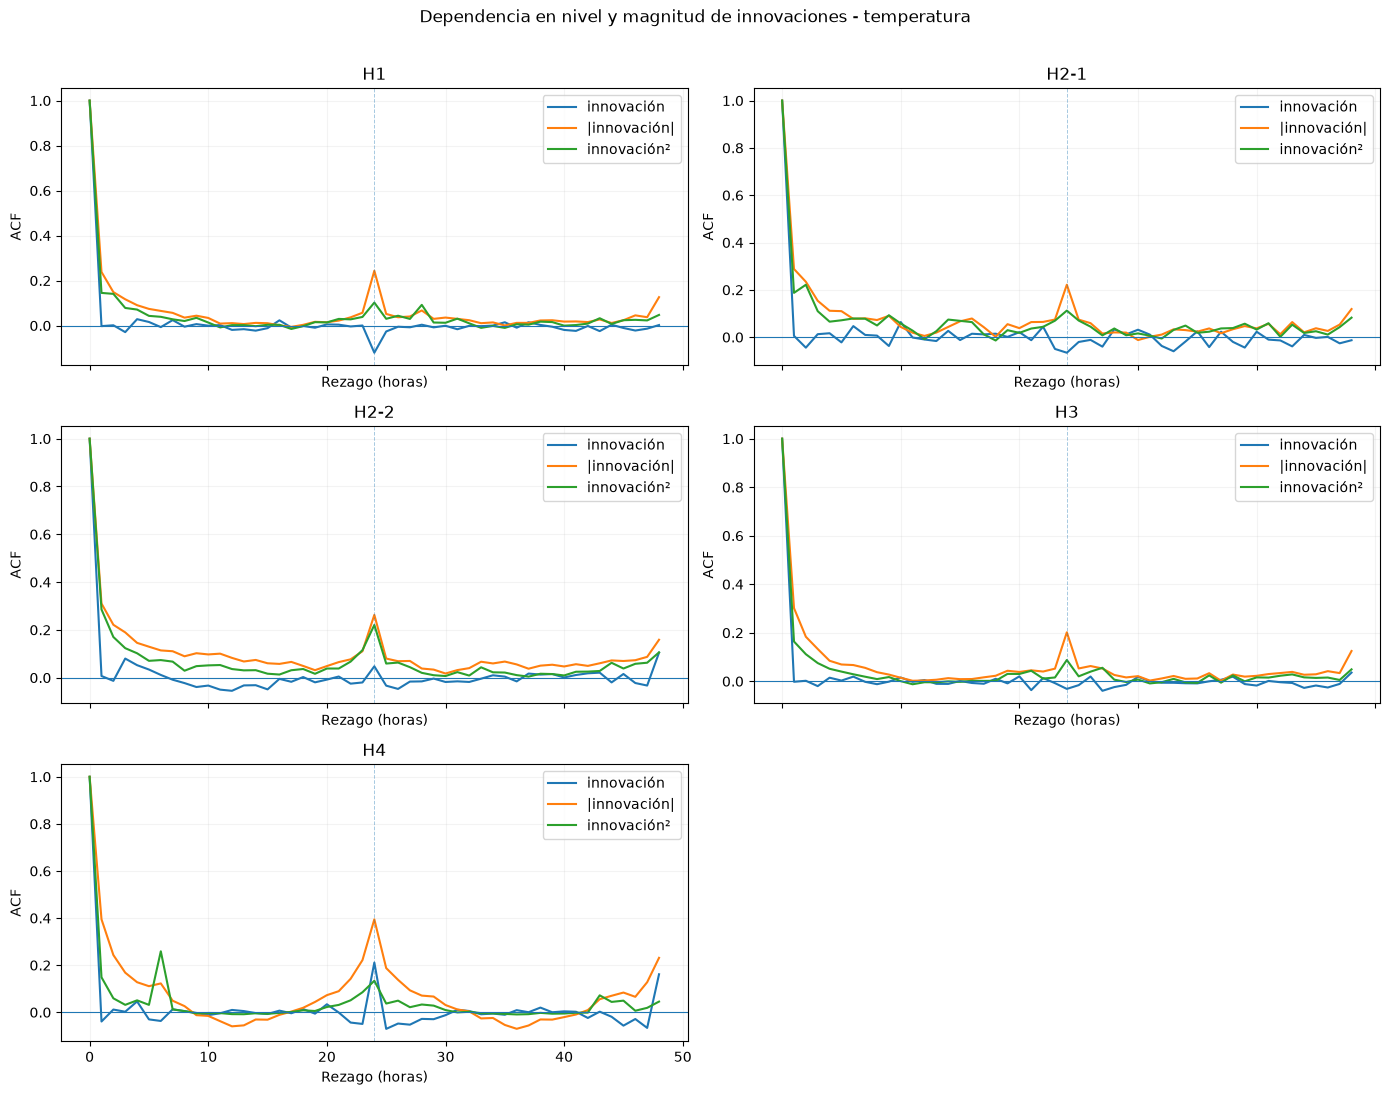

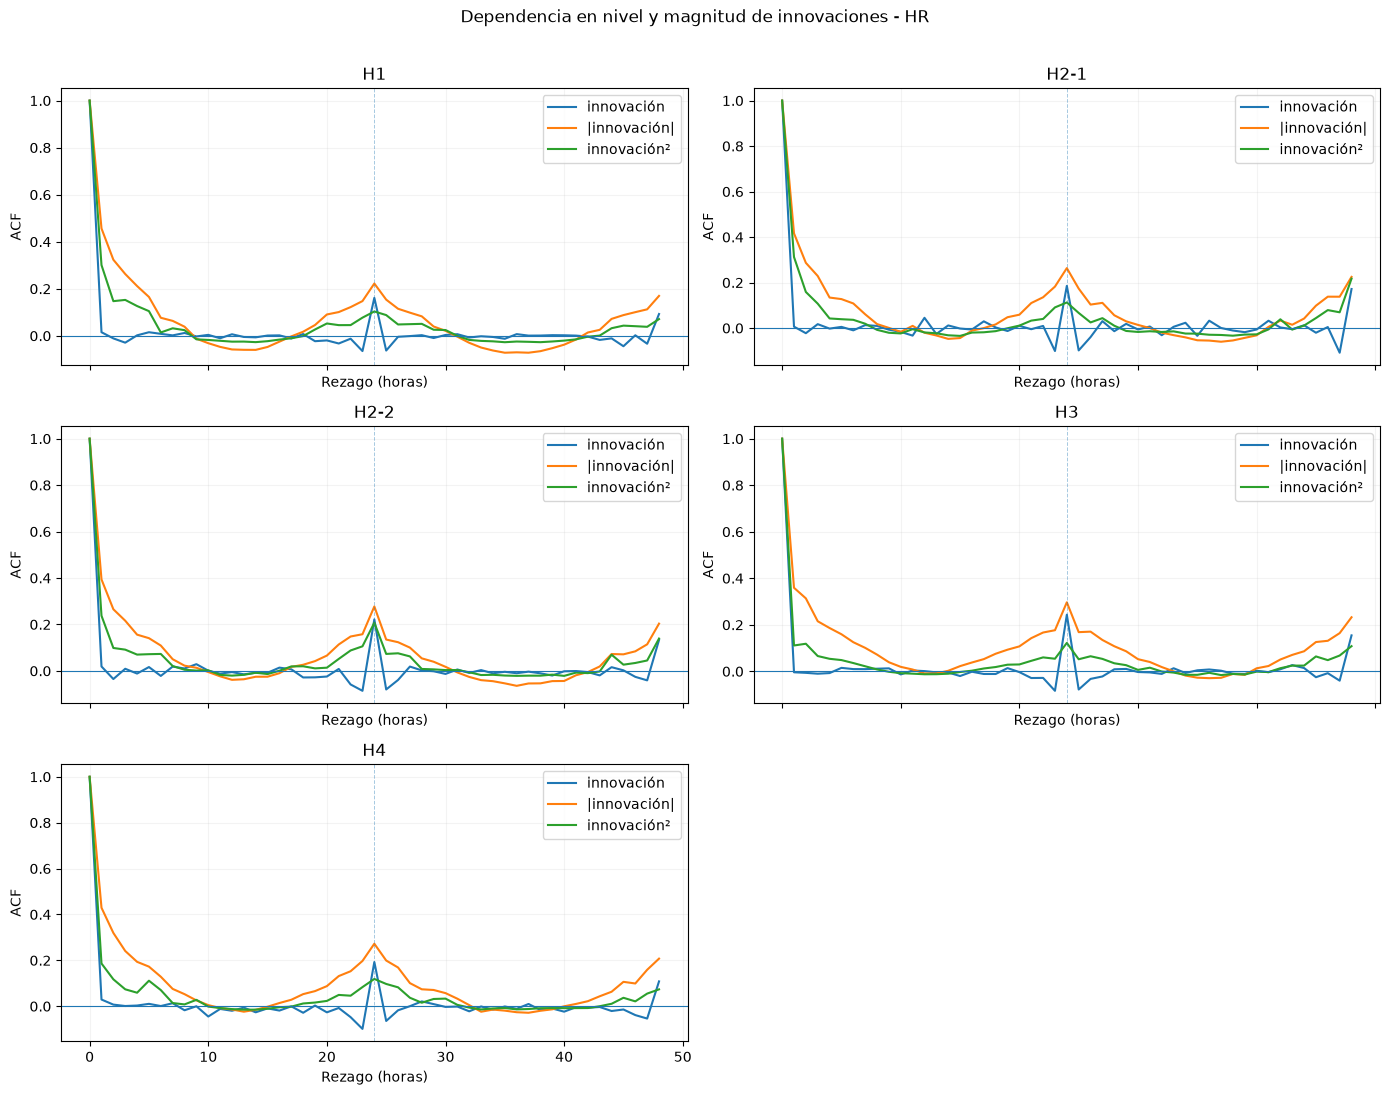

In [21]:
def graficar_acf_magnitud(acf_innov, acf_abs, acf_sq, titulo, max_lag=48):
    unidades = sorted(set(acf_innov) & set(acf_abs) & set(acf_sq))
    ncols = 2
    nrows = int(np.ceil(len(unidades) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.6 * nrows), sharex=True)
    axes = np.atleast_1d(axes).ravel()
    for ax, unidad in zip(axes, unidades):
        objetos = [(acf_innov[unidad], 'innovación'), (acf_abs[unidad], '|innovación|'), (acf_sq[unidad], 'innovación²')]
        for r, etiqueta in objetos:
            rr = r.loc[lambda x: x.index <= max_lag]
            ax.plot(rr.index, rr['correlacion'], label=etiqueta)
        ax.axhline(0, linewidth=0.8)
        ax.axvline(24, linewidth=0.7, linestyle='--', alpha=0.4)
        ax.set_title(unidad)
        ax.set_xlabel('Rezago (horas)')
        ax.set_ylabel('ACF')
        ax.grid(alpha=0.15)
        ax.legend()
    for ax in axes[len(unidades):]:
        ax.remove()
    fig.suptitle(titulo, y=1.01)
    plt.tight_layout()
    plt.show()
graficar_acf_magnitud(
    acf_innov_temp,
    acf_abs_temp,
    acf_sq_temp,
    'Dependencia en nivel y magnitud de innovaciones - temperatura',
)
graficar_acf_magnitud(acf_innov_hr, acf_abs_hr, acf_sq_hr, 'Dependencia en nivel y magnitud de innovaciones - HR')

La magnitud de las innovaciones no se comporta como ruido independiente: los períodos con errores grandes tienden a agruparse. La dependencia aparece en $|\hat\varepsilon_t|$ y en $\hat\varepsilon_t^2$, aun cuando el modelo de media ya haya retirado la estructura lineal más inmediata.

### 3.3 Las innovaciones además presentan colas pesadas

La distribución de las innovaciones se resume mediante cuantiles, asimetría, curtosis y QQ-plots.

Este paso no elige todavía una distribución final. Primero permite distinguir dos fenómenos que pueden mezclarse: cambios en la escala a lo largo del tiempo y colas más pesadas que una Normal.

In [22]:
def resumen_distribucion_innovaciones(innovaciones):
    filas = []
    for unidad, serie in innovaciones.items():
        s = serie.dropna().astype(float)
        if len(s) == 0:
            continue
        mediana = s.median()
        mad = np.median(np.abs(s.to_numpy() - mediana))
        filas.append({
            'unidad': unidad,
            'n': len(s),
            'media': s.mean(),
            'mediana': mediana,
            'std': s.std(),
            'mad': mad,
            'mad_escala_normal': 1.4826 * mad,
            'q0_5': s.quantile(0.005),
            'q2_5': s.quantile(0.025),
            'q25': s.quantile(0.25),
            'q75': s.quantile(0.75),
            'q97_5': s.quantile(0.975),
            'q99_5': s.quantile(0.995),
            'skewness': stats.skew(s, bias=False),
            'kurtosis_exceso': stats.kurtosis(s, fisher=True, bias=False),
        })
    return pd.DataFrame(filas).set_index('unidad')
resumen_innov_temp = resumen_distribucion_innovaciones(innovaciones_temp)
resumen_innov_hr = resumen_distribucion_innovaciones(innovaciones_hr)
print('Distribución de innovaciones - temperatura:')
display(redondear_numericas(resumen_innov_temp, 3))
print('Distribución de innovaciones - HR:')
display(redondear_numericas(resumen_innov_hr, 3))

Distribución de innovaciones - temperatura:


,n,media,mediana,std,mad,mad_escala_normal,q0_5,q2_5,q25,q75,q97_5,q99_5,skewness,kurtosis_exceso
unidad,,,,,,,,,,,,,,
H1,8872,0.001,-0.000,0.117,0.037,0.055,-0.416,-0.264,-0.036,0.039,0.265,0.435,-0.130,7.417
H2-1,2385,0.001,-0.001,0.117,0.032,0.047,-0.423,-0.290,-0.030,0.034,0.278,0.427,-0.041,5.740
H2-2,6350,0.000,0.001,0.163,0.065,0.096,-0.577,-0.346,-0.062,0.067,0.332,0.556,-0.193,5.621
H3,7823,0.000,-0.000,0.115,0.027,0.040,-0.440,-0.285,-0.027,0.027,0.277,0.426,0.041,6.603
H4,7603,0.001,0.000,0.053,0.013,0.020,-0.218,-0.087,-0.013,0.014,0.098,0.239,-1.137,76.400


Distribución de innovaciones - HR:


,n,media,mediana,std,mad,mad_escala_normal,q0_5,q2_5,q25,q75,q97_5,q99_5,skewness,kurtosis_exceso
unidad,,,,,,,,,,,,,,
H1,8872,-0.003,-0.001,0.852,0.141,0.209,-3.902,-1.749,-0.144,0.139,1.758,3.940,-0.625,26.223
H2-1,2385,-0.011,-0.013,0.800,0.182,0.270,-3.478,-1.896,-0.183,0.179,1.701,2.872,-0.428,14.660
H2-2,6350,-0.006,0.001,0.939,0.175,0.259,-4.650,-1.978,-0.168,0.181,1.863,3.788,-0.583,24.485
H3,7823,-0.026,-0.015,0.914,0.147,0.218,-4.577,-1.819,-0.161,0.134,1.719,3.725,-1.785,32.965
H4,7603,-0.008,0.002,0.879,0.121,0.180,-4.660,-1.786,-0.116,0.126,1.678,3.425,-2.025,35.425


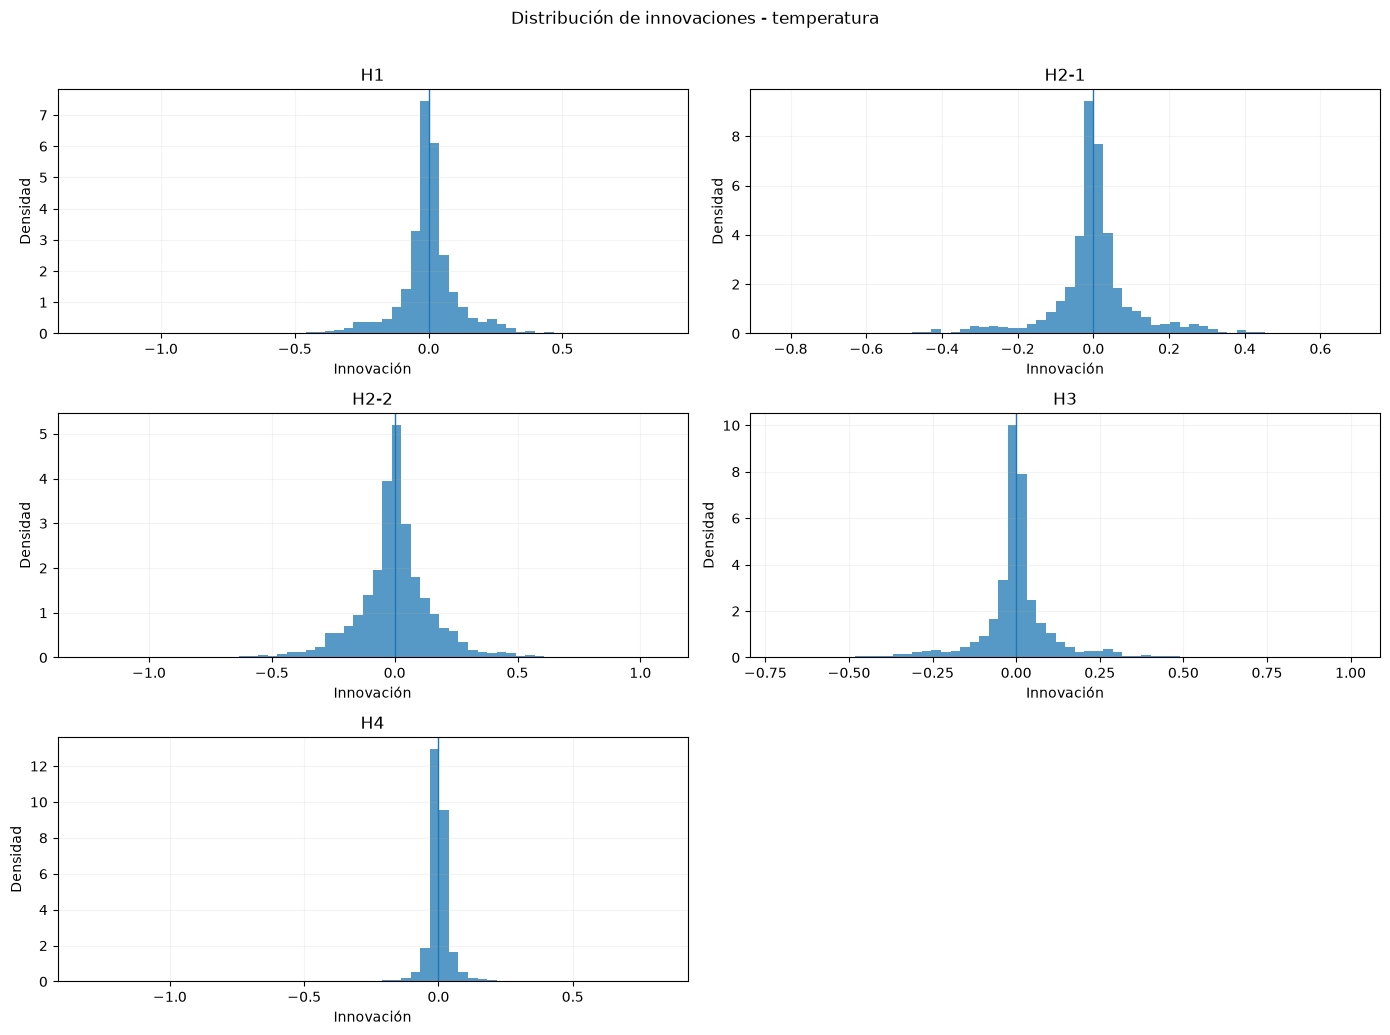

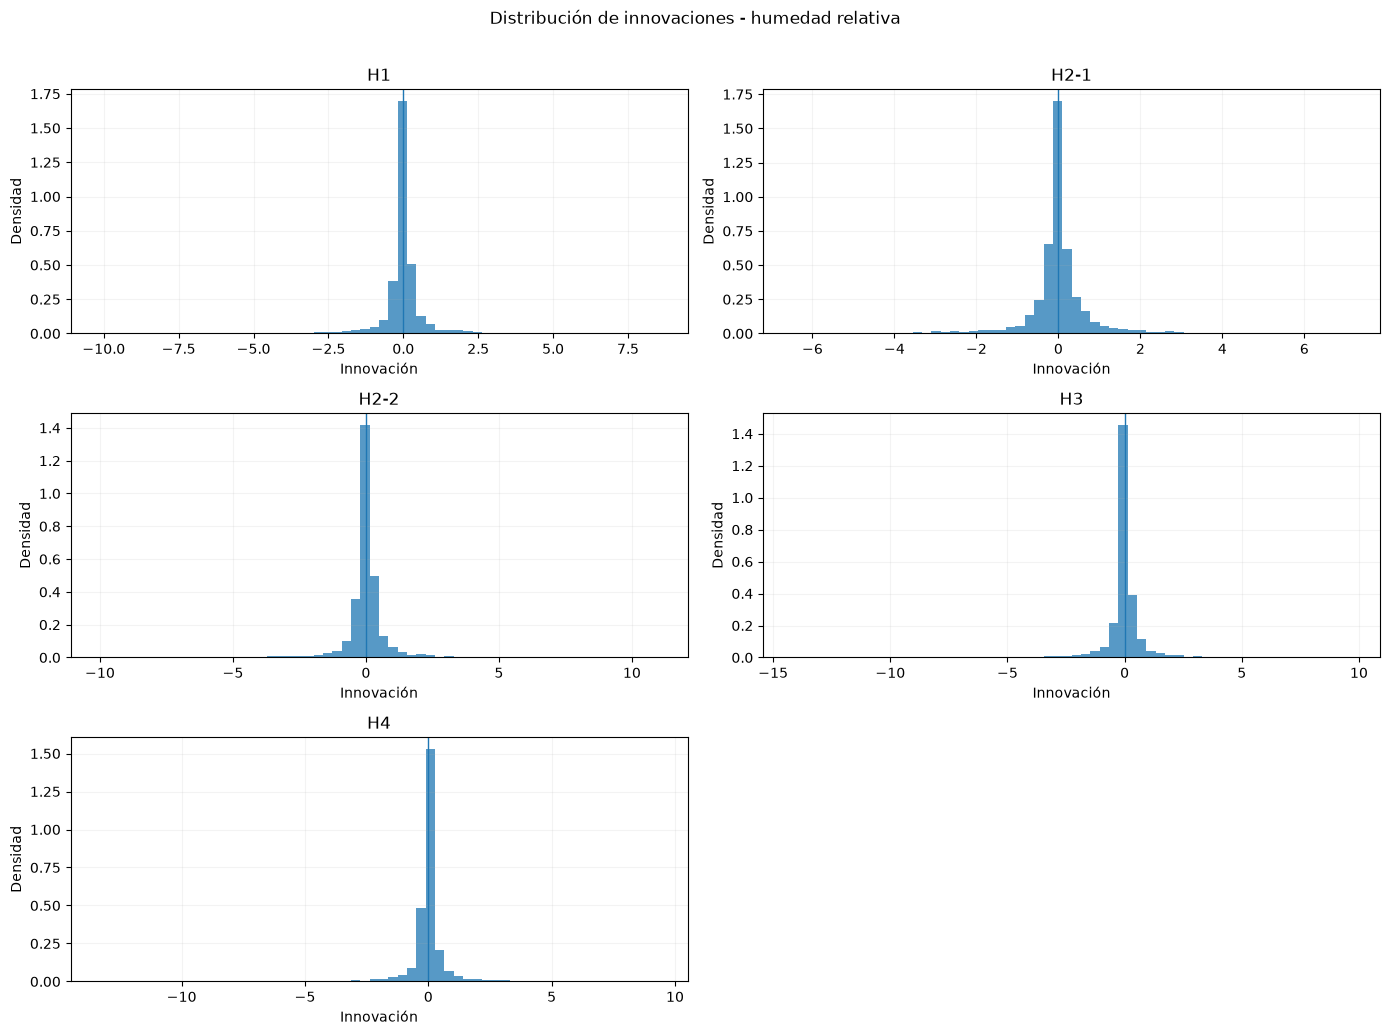

In [23]:
def graficar_histogramas_innovaciones(innovaciones, titulo, bins=60):
    unidades = list(innovaciones.keys())
    ncols = 2
    nrows = int(np.ceil(len(unidades) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.4 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, unidad in zip(axes, unidades):
        s = innovaciones[unidad].dropna()
        ax.hist(s, bins=bins, density=True, alpha=0.75)
        ax.axvline(0, linewidth=1)
        ax.set_title(unidad)
        ax.set_xlabel('Innovación')
        ax.set_ylabel('Densidad')
        ax.grid(alpha=0.15)
    for ax in axes[len(unidades):]:
        ax.remove()
    fig.suptitle(titulo, y=1.01)
    plt.tight_layout()
    plt.show()
graficar_histogramas_innovaciones(innovaciones_temp, 'Distribución de innovaciones - temperatura')
graficar_histogramas_innovaciones(innovaciones_hr, 'Distribución de innovaciones - humedad relativa')

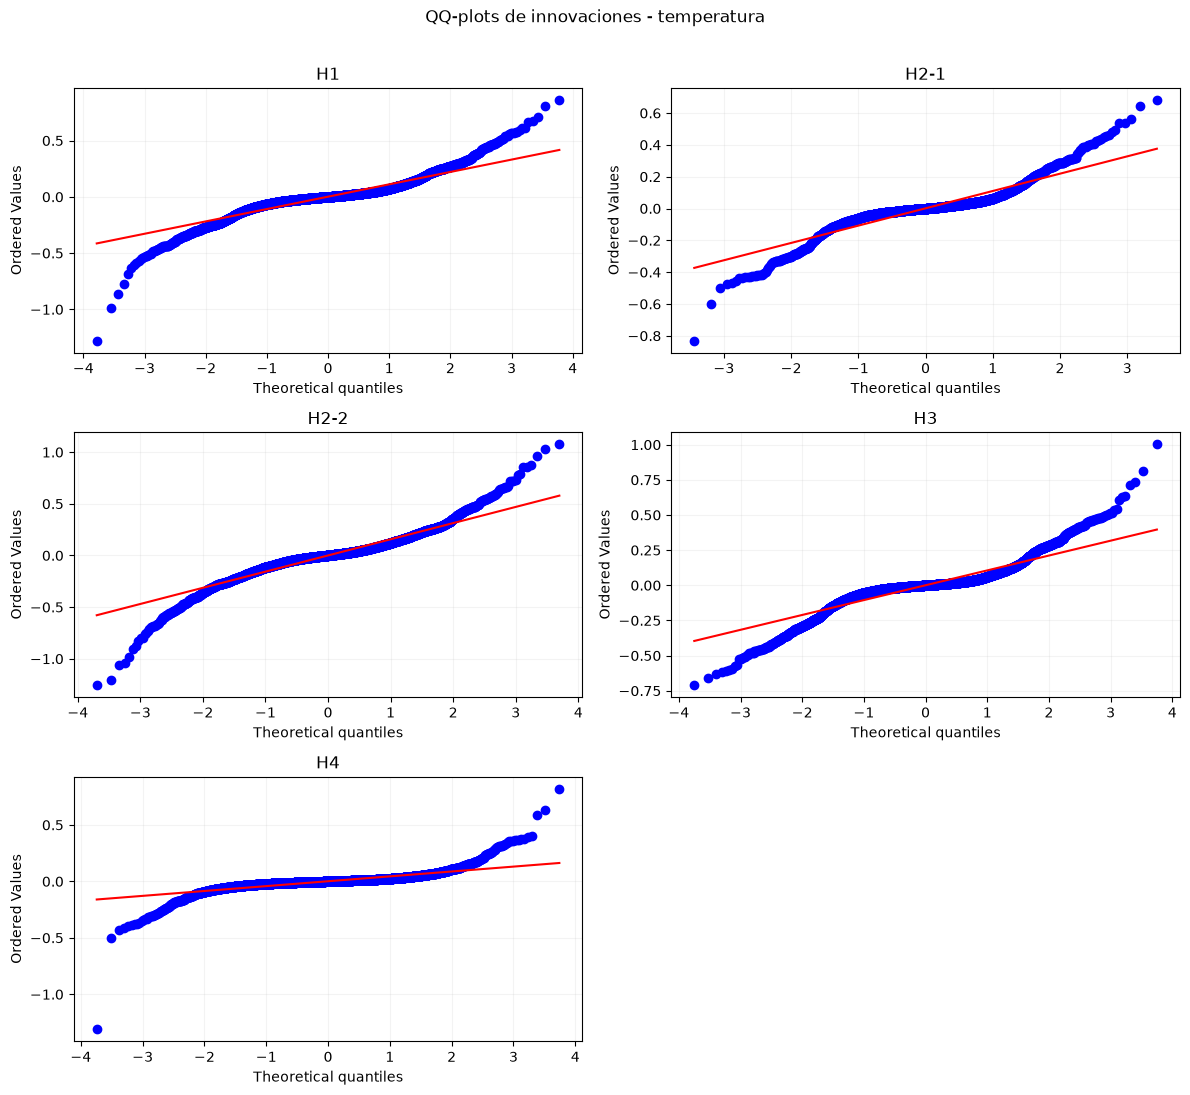

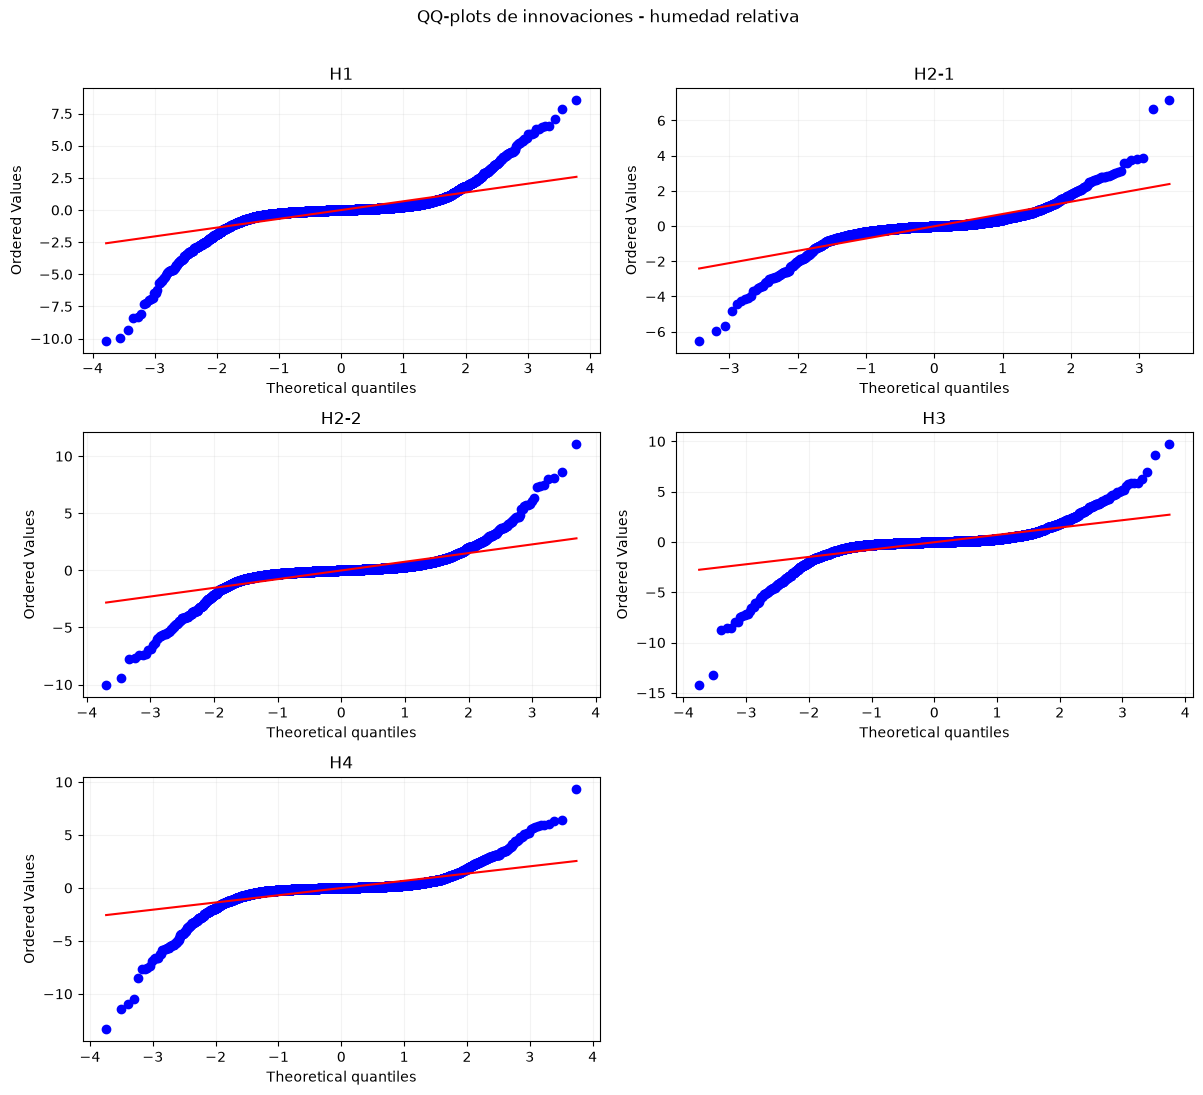

In [24]:
def graficar_qq_innovaciones(innovaciones, titulo):
    unidades = list(innovaciones.keys())
    ncols = 2
    nrows = int(np.ceil(len(unidades) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, unidad in zip(axes, unidades):
        s = innovaciones[unidad].dropna().to_numpy()
        stats.probplot(s, dist='norm', plot=ax)
        ax.set_title(unidad)
        ax.grid(alpha=0.15)
    for ax in axes[len(unidades):]:
        ax.remove()
    fig.suptitle(titulo, y=1.01)
    plt.tight_layout()
    plt.show()
graficar_qq_innovaciones(innovaciones_temp, 'QQ-plots de innovaciones - temperatura')
graficar_qq_innovaciones(innovaciones_hr, 'QQ-plots de innovaciones - humedad relativa')

Las innovaciones están centradas cerca de cero, pero sus colas son mucho más pesadas que las de una Normal. En T, la curtosis en exceso va de 5,6 a 7,4 en H1–H3 y alcanza 76 en H4; en HR se ubica entre 14,7 y 35,4. Los QQ-plots muestran que el ajuste es razonablemente mejor en la zona central y se deteriora con claridad hacia los extremos.

### 3.4 Síntesis de los diagnósticos

Los diagnósticos muestran variaciones temporales en la dispersión de las innovaciones, dependencia en la magnitud de los errores y colas más pesadas que las de una distribución Normal.

En conjunto, estos resultados justifican examinar la presencia de heterocedasticidad condicional y evaluar una especificación que permita modelar la escala residual a lo largo del tiempo. La elección del detector operativo se realizará posteriormente, a partir de la comparación entre alternativas.

## 4. De los diagnósticos de las innovaciones al modelo GARCH-t

Para estudiar si parte de esta variabilidad puede representarse mediante una escala que cambie en el tiempo, primero se aplica el contraste ARCH-LM. A partir de sus resultados, se ajusta un modelo GARCH(1,1) con innovaciones normales y se examina la distribución de los residuos estandarizados.

Posteriormente, se considera una distribución Student-t para representar las colas que permanecen después de modelar la volatilidad condicional.

El objetivo de esta etapa es construir y evaluar una alternativa más flexible a la escala residual global, cuya utilidad para la detección de anomalías se examinará mediante la comparación de ambas especificaciones.

### 4.1 ARCH-LM: ¿hay evidencia de varianza condicional?

ARCH-LM se aplica por bloque continuo, porque los huecos del registro rompen la secuencia temporal sobre la que se construyen los rezagos.

In [25]:
ARCH_LAGS = 24
ALPHA_ARCH = 0.05
MIN_OBS_ARCH_BLOQUE = 24 * 7


def separar_bloques_innovacion(serie, min_obs=50):
    s = serie.dropna().astype(float).sort_index()

    if s.empty:
        return []

    cortes = s.index.to_series().diff().ne(pd.Timedelta(hours=1))
    grupos = cortes.cumsum()

    return [
        bloque
        for _, bloque in s.groupby(grupos.to_numpy())
        if len(bloque) >= min_obs
    ]



def tabla_arch_lm_por_bloque(innovaciones, variable):
    filas = []

    for unidad, serie in innovaciones.items():
        bloques = separar_bloques_innovacion(
            serie,
            min_obs=MIN_OBS_ARCH_BLOQUE,
        )

        if not bloques:
            filas.append({
                'variable': variable,
                'unidad': unidad,
                'bloque_id': pd.NA,
                'n': 0,
                'inicio': pd.NaT,
                'fin': pd.NaT,
                'lm_stat': np.nan,
                'lm_p': np.nan,
                'f_stat': np.nan,
                'f_p': np.nan,
                'testeado': False,
            })
            continue

        for bloque_id, s in enumerate(bloques, start=1):
            lm_stat, lm_p, f_stat, f_p = het_arch(
                s.astype(float),
                nlags=ARCH_LAGS,
            )

            filas.append({
                'variable': variable,
                'unidad': unidad,
                'bloque_id': bloque_id,
                'n': len(s),
                'inicio': s.index.min(),
                'fin': s.index.max(),
                'lm_stat': lm_stat,
                'lm_p': lm_p,
                'f_stat': f_stat,
                'f_p': f_p,
                'testeado': True,
            })

    return (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad', 'bloque_id'])
        .sort_index()
    )


def resumir_arch_por_unidad(tabla):
    filas = []

    base = tabla.reset_index()

    for (variable, unidad), grupo in base.groupby(['variable', 'unidad']):
        testeados = grupo.loc[grupo['testeado'].astype(bool)].copy()

        if testeados.empty:
            filas.append({
                'variable': variable,
                'unidad': unidad,
                'n_bloques_testeados': 0,
                'n_bloques_significativos': 0,
                'min_arch_lm_p': np.nan,
                'arch_detectado': False,
            })
            continue

        significativos = testeados['lm_p'] < ALPHA_ARCH

        filas.append({
            'variable': variable,
            'unidad': unidad,
            'n_bloques_testeados': len(testeados),
            'n_bloques_significativos': int(significativos.sum()),
            'min_arch_lm_p': testeados['lm_p'].min(),
            'arch_detectado': bool(significativos.any()),
        })

    return (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad'])
        .sort_index()
    )


arch_temp_bloques = tabla_arch_lm_por_bloque(
    innovaciones_temp,
    'T',
)

arch_hr_bloques = tabla_arch_lm_por_bloque(
    innovaciones_hr,
    'HR',
)

arch_resumen = resumir_arch_por_unidad(
    pd.concat([arch_temp_bloques, arch_hr_bloques])
)

print('ARCH-LM por bloque continuo:')
display(redondear_numericas(
    pd.concat([arch_temp_bloques, arch_hr_bloques]),
    4,
))

print('\nResumen ARCH-LM por unidad:')
display(redondear_numericas(arch_resumen, 4))

ARCH-LM por bloque continuo:


n              inicio                 fin  \
variable unidad bloque_id                                                 
T        H1     1          1849 2022-12-29 14:00:00 2023-03-16 14:00:00   
                2          1848 2023-03-16 16:00:00 2023-06-01 15:00:00   
                3          1985 2023-06-01 17:00:00 2023-08-23 09:00:00   
                4          3190 2023-08-24 17:00:00 2024-01-04 14:00:00   
         H2-1   1          1849 2022-12-29 14:00:00 2023-03-16 14:00:00   
                2           536 2023-03-16 16:00:00 2023-04-07 23:00:00   
         H2-2   1          1144 2023-04-15 00:00:00 2023-06-01 15:00:00   
                2          5206 2023-06-01 17:00:00 2024-01-04 14:00:00   
         H3     1          1849 2022-12-29 14:00:00 2023-03-16 14:00:00   
                2          1848 2023-03-16 16:00:00 2023-06-01 15:00:00   
                3          1985 2023-06-01 17:00:00 2023-08-23 09:00:00   
                4           289 2023-08-24 17:00:00 2023-09-05 17:00:00   
                5          1852 2023-10-19 11:00:00 2024-01-04 14:00:00   
         H4     1          1849 2022-12-29 14:00:00 2023-03-16 14:00:00   
                2          1848 2023-03-16 16:00:00 2023-06-01 15:00:00   
                3           716 2023-06-01 17:00:00 2023-07-01 12:00:00   
                4          3190 2023-08-24 17:00:00 2024-01-04 14:00:00   
HR       H1     1          1849 2022-12-29 14:00:00 2023-03-16 14:00:00   
                2          1848 2023-03-16 16:00:00 2023-06-01 15:00:00   
                3          1985 2023-06-01 17:00:00 2023-08-23 09:00:00   
                4          3190 2023-08-24 17:00:00 2024-01-04 14:00:00   
         H2-1   1          1849 2022-12-29 14:00:00 2023-03-16 14:00:00   
                2           536 2023-03-16 16:00:00 2023-04-07 23:00:00   
         H2-2   1          1144 2023-04-15 00:00:00 2023-06-01 15:00:00   
                2          5206 2023-06-01 17:00:00 2024-01-04 14:00:00   
         H3     1          1849 2022-12-29 14:00:00 2023-03-16 14:00:00   
                2          1848 2023-03-16 16:00:00 2023-06-01 15:00:00   
                3          1985 2023-06-01 17:00:00 2023-08-23 09:00:00   
                4           289 2023-08-24 17:00:00 2023-09-05 17:00:00   
                5          1852 2023-10-19 11:00:00 2024-01-04 14:00:00   
         H4     1          1849 2022-12-29 14:00:00 2023-03-16 14:00:00   
                2          1848 2023-03-16 16:00:00 2023-06-01 15:00:00   
                3           716 2023-06-01 17:00:00 2023-07-01 12:00:00   
                4          3190 2023-08-24 17:00:00 2024-01-04 14:00:00   

                            lm_stat    lm_p   f_stat     f_p  testeado  
variable unidad bloque_id                                               
T        H1     1          136.0497  0.0000   6.0415  0.0000      True  
                2          174.1635  0.0000   7.9129  0.0000      True  
                3           63.1062  0.0000   2.6822  0.0000      True  
                4          217.2529  0.0000   9.6424  0.0000      True  
         H2-1   1          129.2528  0.0000   5.7166  0.0000      True  
                2          126.0256  0.0000   6.6255  0.0000      True  
         H2-2   1          197.7212  0.0000   9.7812  0.0000      True  
                2          488.9339  0.0000  22.3862  0.0000      True  
         H3     1          135.0975  0.0000   5.9958  0.0000      True  
                2          105.1037  0.0000   4.5834  0.0000      True  
                3           86.6289  0.0000   3.7282  0.0000      True  
                4           57.7470  0.0001   2.7863  0.0000      True  
                5           96.2368  0.0000   4.1748  0.0000      True  
         H4     1          259.1796  0.0000  12.4142  0.0000      True  
                2          646.8763  0.0000  41.1926  0.0000      True  
                3          155.1721  0.0000   8.0333  0.0000      True  
               


Resumen ARCH-LM por unidad:


n_bloques_testeados  n_bloques_significativos  min_arch_lm_p  \
variable unidad                                                                 
HR       H1                        4                         4            0.0   
         H2-1                      2                         2            0.0   
         H2-2                      2                         2            0.0   
         H3                        5                         3            0.0   
         H4                        4                         3            0.0   
T        H1                        4                         4            0.0   
         H2-1                      2                         2            0.0   
         H2-2                      2                         2            0.0   
         H3                        5                         5            0.0   
         H4                        4                         4            0.0   

                 arch_detectado  
variable unidad                  
HR       H1                True  
         H2-1              True  
         H2-2              True  
         H3                True  
         H4                True  
T        H1                True  
         H2-1              True  
         H2-2              True  
         H3                True  
         H4                True

ARCH-LM encuentra evidencia de varianza condicional en las diez series. En T son significativos los 17 bloques testeados; en HR lo son 14 de 17. Los pocos bloques no significativos corresponden a segmentos específicos de H3 y H4 y no eliminan la evidencia global por unidad.

La hipótesis de una única varianza constante resulta, por lo tanto, demasiado restrictiva como descripción de las innovaciones.

### 4.2 GARCH(1,1)-Normal: ¿modelar la escala alcanza?

Dado que ARCH-LM detecta heterocedasticidad condicional, se ajusta

$$
\sigma_t^2
=
\omega
+
\alpha\varepsilon_{t-1}^2
+
\beta\sigma_{t-1}^2.
$$

La versión Normal permite separar dos preguntas: cuánto de la dependencia en la escala absorbe GARCH y si, una vez estandarizadas las innovaciones, las colas siguen siendo demasiado pesadas para una Normal.

In [26]:
def parametros_garch_desde_theta(theta):
    log_var_largo = theta[0]
    ea = np.exp(np.clip(theta[1], -30, 30))
    eb = np.exp(np.clip(theta[2], -30, 30))
    denom = 1 + ea + eb
    alpha = 0.999 * ea / denom
    beta = 0.999 * eb / denom
    var_largo = np.exp(log_var_largo)
    omega = var_largo * (1 - alpha - beta)
    return (omega, alpha, beta, var_largo)

def nll_garch_normal(theta, bloques):
    omega, alpha, beta, var_largo = parametros_garch_desde_theta(theta)
    nll = 0.0
    for bloque in bloques:
        x = bloque.to_numpy(dtype=float)
        h = var_largo
        for e in x:
            if h <= 1e-14 or not np.isfinite(h):
                return 1e+100
            nll += 0.5 * (np.log(2 * np.pi) + np.log(h) + e ** 2 / h)
            h = omega + alpha * e ** 2 + beta * h
    return float(nll)

def ajustar_garch_normal(serie):
    bloques = separar_bloques_innovacion(serie)
    if len(bloques) == 0:
        raise ValueError('No hay bloques continuos suficientemente largos para ajustar GARCH.')
    x = np.concatenate([bloque.to_numpy(dtype=float) for bloque in bloques])
    var0 = max(np.var(x), 1e-08)
    inicios = [
        np.array([np.log(var0), -2.0, 2.0]),
        np.array([np.log(var0), -1.0, 3.0]),
        np.array([np.log(var0), 0.0, 2.0]),
    ]
    mejor = None
    for inicio in inicios:
        ajuste = optimize.minimize(
            nll_garch_normal,
            x0=inicio,
            args=(bloques,),
            method='L-BFGS-B',
            options={'maxiter': 1000},
        )
        if mejor is None or ajuste.fun < mejor.fun:
            mejor = ajuste
    omega, alpha, beta, var_largo = parametros_garch_desde_theta(mejor.x)
    var_condicional = []
    for bloque in bloques:
        h = var_largo
        valores_h = []
        for e in bloque.to_numpy(dtype=float):
            valores_h.append(h)
            h = omega + alpha * e ** 2 + beta * h
        var_condicional.append(pd.Series(valores_h, index=bloque.index, name='var_condicional'))
    h = pd.concat(var_condicional).sort_index()
    innovacion = serie.reindex(h.index).astype(float)
    z = (innovacion / np.sqrt(h)).rename('z_garch')
    loglik = -mejor.fun
    k = 3
    n = len(x)
    return {
        'omega': omega,
        'alpha': alpha,
        'beta': beta,
        'alpha_beta': alpha + beta,
        'var_largo': var_largo,
        'loglik': loglik,
        'aic': 2 * k - 2 * loglik,
        'bic': np.log(n) * k - 2 * loglik,
        'n': n,
        'convergio': bool(mejor.success),
        'var_condicional': h,
        'z_estandarizado': z,
    }

In [27]:
def diagnostico_arch_post(serie, arch_lags=ARCH_LAGS):
    bloques = separar_bloques_innovacion(
        serie,
        min_obs=arch_lags + 6,
    )

    p_values = []

    for bloque in bloques:
        _, lm_p, _, _ = het_arch(
            bloque.astype(float),
            nlags=arch_lags,
        )
        p_values.append(lm_p)

    return {
        'n_bloques_arch_post': len(p_values),
        'min_arch_lm_p_post': min(p_values) if p_values else np.nan,
        'n_bloques_arch_post_sig': sum(p < ALPHA_ARCH for p in p_values),
    }


def diagnosticar_garch(serie):
    ajuste = ajustar_garch_normal(serie)
    z = ajuste['z_estandarizado'].dropna().astype(float)

    diag_arch = diagnostico_arch_post(z)
    acf_z2 = acf_pairwise(z ** 2, max_lag=1)
    acf_lag1 = (
        acf_z2.loc[1, 'correlacion']
        if 1 in acf_z2.index
        else np.nan
    )

    return (
        ajuste,
        {
            'omega': ajuste['omega'],
            'alpha': ajuste['alpha'],
            'beta': ajuste['beta'],
            'alpha_beta': ajuste['alpha_beta'],
            'n': ajuste['n'],
            'convergio': ajuste['convergio'],
            'media_z': z.mean(),
            'sd_z': z.std(ddof=1),
            'curtosis_z': (
                stats.kurtosis(z, fisher=False, bias=False)
                if len(z) > 3
                else np.nan
            ),
            'acf_z2_lag1': acf_lag1,
            **diag_arch,
        },
    )


def ajustar_garch_coleccion(innovaciones, variable):
    modelos = {}
    filas = []

    for unidad, serie in innovaciones.items():
        clave = (variable, unidad)

        if clave not in arch_resumen.index:
            continue

        if not bool(arch_resumen.loc[clave, 'arch_detectado']):
            continue

        ajuste, diag = diagnosticar_garch(serie)
        modelos[unidad] = ajuste

        filas.append({
            'variable': variable,
            'unidad': unidad,
            'min_arch_lm_p_pre': arch_resumen.loc[clave, 'min_arch_lm_p'],
            **diag,
        })

    if not filas:
        return modelos, pd.DataFrame()

    tabla = (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad'])
        .sort_index()
    )

    return modelos, tabla


garch_temp, diag_garch_temp = ajustar_garch_coleccion(
    innovaciones_temp,
    'T',
)

garch_hr, diag_garch_hr = ajustar_garch_coleccion(
    innovaciones_hr,
    'HR',
)

print('GARCH(1,1)-Normal - temperatura:')
display(redondear_numericas(diag_garch_temp, 4))

print('\nGARCH(1,1)-Normal - HR:')
display(redondear_numericas(diag_garch_hr, 4))

GARCH(1,1)-Normal - temperatura:


min_arch_lm_p_pre   omega   alpha    beta  alpha_beta     n  \
variable unidad                                                                
T        H1                    0.0  0.0026  0.1082  0.7024      0.8106  8872   
         H2-1                  0.0  0.0025  0.1221  0.6912      0.8134  2385   
         H2-2                  0.0  0.0032  0.2029  0.6825      0.8853  6350   
         H3                    0.0  0.0039  0.1853  0.5361      0.7214  7823   
         H4                    0.0  0.0004  0.6485  0.3480      0.9965  7603   

                 convergio  media_z    sd_z  curtosis_z  acf_z2_lag1  \
variable unidad                                                        
T        H1           True   0.0102  0.9979     11.5903       0.0057   
         H2-1         True   0.0095  1.0003     10.6931      -0.0009   
         H2-2         True   0.0060  1.0007      7.1644       0.0131   
         H3           True   0.0020  0.9992     11.4193      -0.0039   
         H4           True   0.0170  1.0176     35.5403      -0.0016   

                 n_bloques_arch_post  min_arch_lm_p_post  \
variable unidad                                            
T        H1                        4              0.0092   
         H2-1                      2              0.2687   
         H2-2                      2              0.0000   
         H3                        5              0.0377   
         H4                        4              0.0000   

                 n_bloques_arch_post_sig  
variable unidad                           
T        H1                            2  
         H2-1                          0  
         H2-2                          2  
         H3                            1  
         H4                            3


GARCH(1,1)-Normal - HR:


min_arch_lm_p_pre   omega   alpha    beta  alpha_beta     n  \
variable unidad                                                                
HR       H1                    0.0  0.1244  0.5880  0.3942      0.9821  8872   
         H2-1                  0.0  0.1207  0.5895  0.3789      0.9684  2385   
         H2-2                  0.0  0.1705  0.6126  0.3709      0.9835  6350   
         H3                    0.0  0.1932  0.5171  0.4349      0.9521  7823   
         H4                    0.0  0.2119  0.7341  0.2409      0.9750  7603   

                 convergio  media_z    sd_z  curtosis_z  acf_z2_lag1  \
variable unidad                                                        
HR       H1           True   0.0157  1.0175     66.2376      -0.0014   
         H2-1         True  -0.0082  1.0055     27.8910      -0.0080   
         H2-2         True  -0.0030  1.0235     51.0604      -0.0029   
         H3           True  -0.0294  1.0036     96.0999      -0.0045   
         H4           True   0.0006  1.0124    114.1604      -0.0039   

                 n_bloques_arch_post  min_arch_lm_p_post  \
variable unidad                                            
HR       H1                        4              0.8423   
         H2-1                      2              0.0005   
         H2-2                      2              0.0000   
         H3                        5              0.0013   
         H4                        4              0.0000   

                 n_bloques_arch_post_sig  
variable unidad                           
HR       H1                            0  
         H2-1                          1  
         H2-2                          1  
         H3                            1  
         H4                            1

GARCH-Normal estandariza razonablemente la escala inmediata: las desviaciones de $z_t$ quedan próximas a 1 y la ACF de $z_t^2$ en lag 1 es prácticamente nula. Sin embargo, las colas siguen siendo incompatibles con una Normal: la curtosis de los residuos estandarizados permanece entre 7 y 36 en T y entre 28 y 114 en HR.

Modelar sólo la volatilidad no alcanza; queda un problema distribucional en los extremos.

### 4.3 GARCH(1,1)-Student: misma escala dinámica, colas más flexibles

Dado que GARCH-Normal no representa adecuadamente las colas de las innovaciones, se evalúa una especificación GARCH(1,1) con distribución Student-t estandarizada.

Se mantiene la misma estructura de volatilidad condicional y se modifica la distribución de las innovaciones estandarizadas. Ambos modelos se ajustan sobre las mismas series, lo que permite comparar sus resultados.

In [28]:
def nu_desde_theta(theta_nu):
    """
    Parametrización:

        nu = 2.05 + exp(theta_nu)

    Garantiza nu > 2.
    """
    return 2.05 + np.exp(np.clip(theta_nu, -10, 7))

def nll_garch_student(theta, bloques):
    """
    Modelo:

        e_t = sqrt(h_t) z_t

        z_t ~ Student-t estandarizada

        h_t =
            omega
            + alpha e_{t-1}^2
            + beta h_{t-1}

    La Student se escala para que:

        E(z_t) = 0
        Var(z_t) = 1

    para nu > 2.
    """
    omega, alpha, beta, var_largo = parametros_garch_desde_theta(theta[:3])
    nu = nu_desde_theta(theta[3])
    log_constante = gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
    nll = 0.0
    for bloque in bloques:
        x = bloque.to_numpy(dtype=float)
        h = var_largo
        for e in x:
            if h <= 1e-14 or not np.isfinite(h):
                return 1e+100
            z2 = e ** 2 / h
            log_densidad = log_constante - 0.5 * np.log(h) - (nu + 1) / 2 * np.log1p(z2 / (nu - 2))
            if not np.isfinite(log_densidad):
                return 1e+100
            nll -= log_densidad
            h = omega + alpha * e ** 2 + beta * h
    return float(nll)

def ajustar_garch_student(serie):
    """
    Ajusta:

        GARCH(1,1)
        +
        Student-t estandarizada

    sobre las innovaciones del modelo de media.
    """
    bloques = separar_bloques_innovacion(serie)
    if len(bloques) == 0:
        raise ValueError('No hay bloques continuos suficientemente largos para ajustar GARCH-Student.')
    x = np.concatenate([bloque.to_numpy(dtype=float) for bloque in bloques])
    var0 = max(np.var(x), 1e-08)
    nus_iniciales = [4.0, 8.0, 20.0]
    inicios_garch = [(-2.0, 2.0), (-1.0, 3.0), (0.0, 2.0)]
    inicios = []
    for (theta_alpha, theta_beta), nu0 in zip(inicios_garch, nus_iniciales):
        theta_nu0 = np.log(max(nu0 - 2.05, 1e-06))
        inicios.append(np.array([np.log(var0), theta_alpha, theta_beta, theta_nu0]))
    mejor = None
    for inicio in inicios:
        ajuste = optimize.minimize(
            nll_garch_student,
            x0=inicio,
            args=(bloques,),
            method='L-BFGS-B',
            options={'maxiter': 1500},
        )
        if mejor is None or ajuste.fun < mejor.fun:
            mejor = ajuste
    if mejor is None or not np.isfinite(mejor.fun):
        raise RuntimeError('No se obtuvo un ajuste GARCH-Student válido.')
    omega, alpha, beta, var_largo = parametros_garch_desde_theta(mejor.x[:3])
    nu = nu_desde_theta(mejor.x[3])
    var_condicional = []
    for bloque in bloques:
        h = var_largo
        valores_h = []
        for e in bloque.to_numpy(dtype=float):
            valores_h.append(h)
            h = omega + alpha * e ** 2 + beta * h
        var_condicional.append(pd.Series(valores_h, index=bloque.index, name='var_condicional'))
    h = pd.concat(var_condicional).sort_index()
    innovacion = serie.reindex(h.index).astype(float)
    z = (innovacion / np.sqrt(h)).rename('z_garch_student')
    loglik = -mejor.fun
    k = 4
    n = len(x)
    return {
        'omega': omega,
        'alpha': alpha,
        'beta': beta,
        'alpha_beta': alpha + beta,
        'nu': nu,
        'var_largo': var_largo,
        'loglik': loglik,
        'aic': 2 * k - 2 * loglik,
        'bic': np.log(n) * k - 2 * loglik,
        'n': n,
        'convergio': bool(mejor.success),
        'mensaje_optimizacion': mejor.message,
        'var_condicional': h,
        'z_estandarizado': z,
    }


def diagnosticar_garch_student(serie):
    ajuste = ajustar_garch_student(serie)
    z = ajuste['z_estandarizado'].dropna().astype(float)
    nu = ajuste['nu']

    diag_arch = diagnostico_arch_post(z)
    acf_z2 = acf_pairwise(z ** 2, max_lag=1)
    acf_lag1 = (
        acf_z2.loc[1, 'correlacion']
        if 1 in acf_z2.index
        else np.nan
    )

    escala_t = np.sqrt((nu - 2) / nu)
    cobertura = 0.995
    alpha_colas = 1 - cobertura
    p_inf = alpha_colas / 2
    p_sup = 1 - alpha_colas / 2

    q_inf_t = escala_t * stats.t.ppf(p_inf, df=nu)
    q_sup_t = escala_t * stats.t.ppf(p_sup, df=nu)
    fuera_t = (z < q_inf_t) | (z > q_sup_t)

    curtosis_teorica = (
        3 + 6 / (nu - 4)
        if nu > 4
        else np.inf
    )

    return (
        ajuste,
        {
            'omega': ajuste['omega'],
            'alpha': ajuste['alpha'],
            'beta': ajuste['beta'],
            'alpha_beta': ajuste['alpha_beta'],
            'nu': nu,
            'n': ajuste['n'],
            'convergio': ajuste['convergio'],
            'aic': ajuste['aic'],
            'bic': ajuste['bic'],
            'media_z': z.mean(),
            'sd_z': z.std(ddof=1),
            'curtosis_z': (
                stats.kurtosis(z, fisher=False, bias=False)
                if len(z) > 3
                else np.nan
            ),
            'curtosis_teorica_t': curtosis_teorica,
            'acf_z2_lag1': acf_lag1,
            'q_inf_t_99_5': q_inf_t,
            'q_sup_t_99_5': q_sup_t,
            'pct_fuera_t_99_5': 100 * fuera_t.mean(),
            **diag_arch,
        },
    )


def ajustar_garch_student_coleccion(innovaciones, modelos_garch_normal, variable):
    modelos = {}
    filas = []

    for unidad in modelos_garch_normal:
        serie = innovaciones[unidad]
        ajuste, diag = diagnosticar_garch_student(serie)

        modelos[unidad] = ajuste
        filas.append({
            'variable': variable,
            'unidad': unidad,
            **diag,
        })

    if not filas:
        return modelos, pd.DataFrame()

    tabla = (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad'])
        .sort_index()
    )

    return modelos, tabla


garch_t_temp, diag_garch_t_temp = ajustar_garch_student_coleccion(
    innovaciones_temp,
    garch_temp,
    'T',
)

garch_t_hr, diag_garch_t_hr = ajustar_garch_student_coleccion(
    innovaciones_hr,
    garch_hr,
    'HR',
)

print('GARCH(1,1)-Student - temperatura:')
display(redondear_numericas(diag_garch_t_temp, 4))

print('\nGARCH(1,1)-Student - HR:')
display(redondear_numericas(diag_garch_t_hr, 4))


def comparar_garch(normal, student, diag_student, variable):
    filas = []

    for unidad, ajuste_t in student.items():
        ajuste_n = normal[unidad]
        diag_t = diag_student.loc[(variable, unidad)]

        filas.append({
            'variable': variable,
            'unidad': unidad,
            'AIC_normal': ajuste_n['aic'],
            'AIC_student': ajuste_t['aic'],
            'delta_AIC_t_menos_n': ajuste_t['aic'] - ajuste_n['aic'],
            'BIC_normal': ajuste_n['bic'],
            'BIC_student': ajuste_t['bic'],
            'delta_BIC_t_menos_n': ajuste_t['bic'] - ajuste_n['bic'],
            'nu_student': ajuste_t['nu'],
            'min_ARCH_p_post_student': diag_t['min_arch_lm_p_post'],
            'pct_fuera_t_99_5': diag_t['pct_fuera_t_99_5'],
        })

    if not filas:
        return pd.DataFrame()

    return (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad'])
        .sort_index()
    )


comparacion_garch_temp = comparar_garch(
    garch_temp,
    garch_t_temp,
    diag_garch_t_temp,
    'T',
)

comparacion_garch_hr = comparar_garch(
    garch_hr,
    garch_t_hr,
    diag_garch_t_hr,
    'HR',
)

print('\nComparación GARCH-Normal vs Student - temperatura:')
display(redondear_numericas(comparacion_garch_temp, 4))

print('\nComparación GARCH-Normal vs Student - HR:')
display(redondear_numericas(comparacion_garch_hr, 4))

GARCH(1,1)-Student - temperatura:


omega   alpha    beta  alpha_beta      nu     n  convergio  \
variable unidad                                                                
T        H1      0.0073  0.6729  0.3149      0.9878  2.3309  8872       True   
         H2-1    0.0034  0.6456  0.3380      0.9835  2.4175  2385       True   
         H2-2    0.0036  0.3395  0.6377      0.9772  2.9275  6350       True   
         H3      0.0025  0.7084  0.2789      0.9873  2.4143  7823       True   
         H4      0.0003  0.7263  0.2720      0.9983  2.9937  7603       True   

                        aic         bic  media_z    sd_z  curtosis_z  \
variable unidad                                                        
T        H1     -17530.9275 -17502.5649   0.0061  0.8460     14.0958   
         H2-1    -5095.0257  -5071.9179   0.0085  1.0723     16.1515   
         H2-2    -7458.7583  -7431.7335   0.0065  0.9255      7.3550   
         H3     -18024.6267 -17996.7674  -0.0039  1.2553     16.4037   
         H4     -32329.2876 -32301.5424   0.0163  1.1265     39.7782   

                 curtosis_teorica_t  acf_z2_lag1  q_inf_t_99_5  q_sup_t_99_5  \
variable unidad                                                                
T        H1                     inf      -0.0363       -4.0112        4.0112   
         H2-1                   inf      -0.0402       -4.1705        4.1705   
         H2-2                   inf      -0.0123       -4.3216        4.3216   
         H3                     inf      -0.0436       -4.1660        4.1660   
         H4                     inf      -0.0062       -4.3049        4.3049   

                 pct_fuera_t_99_5  n_bloques_arch_post  min_arch_lm_p_post  \
variable unidad                                                              
T        H1                0.4170                    4              0.0000   
         H2-1              1.1321                    2              0.1255   
         H2-2              0.2362                    2              0.0000   
         H3                2.1475                    5              0.0000   
         H4                0.9207                    4              0.0000   

                 n_bloques_arch_post_sig  
variable unidad                           
T        H1                            2  
         H2-1                          0  
         H2-2                          2  
         H3                            4  
         H4                            3


GARCH(1,1)-Student - HR:


omega   alpha    beta  alpha_beta      nu     n  convergio  \
variable unidad                                                                
HR       H1      0.0333  0.6603  0.3342      0.9945  2.6932  8872       True   
         H2-1    0.0571  0.5983  0.3946      0.9928  2.6549  2385       True   
         H2-2    0.0459  0.6563  0.3333      0.9896  2.7570  6350       True   
         H3      0.0290  0.6058  0.3857      0.9915  2.7203  7823       True   
         H4      0.0204  0.6346  0.3605      0.9952  2.6809  7603       True   

                       aic        bic  media_z    sd_z  curtosis_z  \
variable unidad                                                      
HR       H1      7147.0244  7175.3870   0.0323  1.5973    106.3732   
         H2-1    3011.7458  3034.8537  -0.0077  1.2231     30.2774   
         H2-2    7125.0132  7152.0380  -0.0010  1.5653     79.1276   
         H3      7207.9814  7235.8407  -0.0572  1.9104    146.7869   
         H4      4796.1849  4823.9301  -0.0000  2.0708    228.2934   

                 curtosis_teorica_t  acf_z2_lag1  q_inf_t_99_5  q_sup_t_99_5  \
variable unidad                                                                
HR       H1                     inf      -0.0053       -4.3419        4.3419   
         H2-1                   inf      -0.0134       -4.3358        4.3358   
         H2-2                   inf      -0.0067       -4.3447        4.3447   
         H3                     inf      -0.0054       -4.3441        4.3441   
         H4                     inf      -0.0034       -4.3403        4.3403   

                 pct_fuera_t_99_5  n_bloques_arch_post  min_arch_lm_p_post  \
variable unidad                                                              
HR       H1                1.8598                    4              0.9484   
         H2-1              1.2998                    2              0.0000   
         H2-2              1.8425                    2              0.0000   
         H3                2.2626                    5              0.0000   
         H4                1.9203                    4              1.0000   

                 n_bloques_arch_post_sig  
variable unidad                           
HR       H1                            0  
         H2-1                          1  
         H2-2                          1  
         H3                            1  
         H4                            0


Comparación GARCH-Normal vs Student - temperatura:


AIC_normal  AIC_student  delta_AIC_t_menos_n  BIC_normal  \
variable unidad                                                             
T        H1     -13605.2380  -17530.9275           -3925.6895 -13583.9660   
         H2-1    -3739.4029   -5095.0257           -1355.6228  -3722.0720   
         H2-2    -6261.1870   -7458.7583           -1197.5713  -6240.9183   
         H3     -12419.1605  -18024.6267           -5605.4662 -12398.2660   
         H4     -28428.4357  -32329.2876           -3900.8519 -28407.6268   

                 BIC_student  delta_BIC_t_menos_n  nu_student  \
variable unidad                                                 
T        H1      -17502.5649           -3918.5988      2.3309   
         H2-1     -5071.9179           -1349.8459      2.4175   
         H2-2     -7431.7335           -1190.8151      2.9275   
         H3      -17996.7674           -5598.5014      2.4143   
         H4      -32301.5424           -3893.9156      2.9937   

                 min_ARCH_p_post_student  pct_fuera_t_99_5  
variable unidad                                             
T        H1                       0.0000            0.4170  
         H2-1                     0.1255            1.1321  
         H2-2                     0.0000            0.2362  
         H3                       0.0000            2.1475  
         H4                       0.0000            0.9207


Comparación GARCH-Normal vs Student - HR:


AIC_normal  AIC_student  delta_AIC_t_menos_n  BIC_normal  \
variable unidad                                                             
HR       H1      17089.1292    7147.0244           -9942.1049  17110.4012   
         H2-1     4655.8096    3011.7458           -1644.0637   4673.1404   
         H2-2    14022.1574    7125.0132           -6897.1442  14042.4260   
         H3      18001.8612    7207.9814          -10793.8798  18022.7557   
         H4      15786.1716    4796.1849          -10989.9867  15806.9805   

                 BIC_student  delta_BIC_t_menos_n  nu_student  \
variable unidad                                                 
HR       H1        7175.3870           -9935.0142      2.6932   
         H2-1      3034.8537           -1638.2868      2.6549   
         H2-2      7152.0380           -6890.3880      2.7570   
         H3        7235.8407          -10786.9150      2.7203   
         H4        4823.9301          -10983.0504      2.6809   

                 min_ARCH_p_post_student  pct_fuera_t_99_5  
variable unidad                                             
HR       H1                       0.9484            1.8598  
         H2-1                     0.0000            1.2998  
         H2-2                     0.0000            1.8425  
         H3                       0.0000            2.2626  
         H4                       1.0000            1.9203

In [29]:
LB_LAGS = 24


def ljung_box_abs_z(z, lags=LB_LAGS):
    """
    Ljung-Box sobre |z_t| por bloque continuo.

    A diferencia de ARCH-LM sobre z_t^2, sólo requiere varianza finita
    de z_t (nu > 2), condición que cumplen todos los ajustes Student.
    """
    bloques = separar_bloques_innovacion(
        z.dropna().astype(float),
        min_obs=lags + 6,
    )

    p_values = [
        acorr_ljungbox(bloque.abs(), lags=[lags])['lb_pvalue'].iloc[0]
        for bloque in bloques
    ]

    return {
        'n_bloques': len(p_values),
        'n_bloques_sig': sum(p < ALPHA_ARCH for p in p_values),
        'min_p': min(p_values) if p_values else np.nan,
    }


def acf_abs_z_lags(z, lags=(1, 6, 12, 24, 48)):
    """ACF de |z_t| en lags seleccionados, para ubicar dónde queda la dependencia."""
    acf = acf_pairwise(z.dropna().abs(), max(lags))['correlacion']
    return {f'acf_abs_z_lag{lag}': acf.get(lag, np.nan) for lag in lags}


def comparar_rachas_post_garch(normal, student, diag_normal, diag_student, variable):
    filas = []

    for unidad, ajuste_t in student.items():
        lb_n = ljung_box_abs_z(normal[unidad]['z_estandarizado'])
        lb_t = ljung_box_abs_z(ajuste_t['z_estandarizado'])

        filas.append({
            'variable': variable,
            'unidad': unidad,
            'n_bloques': lb_t['n_bloques'],
            'arch_lm_sig_normal': diag_normal.loc[(variable, unidad), 'n_bloques_arch_post_sig'],
            'arch_lm_sig_student': diag_student.loc[(variable, unidad), 'n_bloques_arch_post_sig'],
            'lb_abs_sig_normal': lb_n['n_bloques_sig'],
            'lb_abs_sig_student': lb_t['n_bloques_sig'],
            'lb_abs_min_p_student': lb_t['min_p'],
            **acf_abs_z_lags(ajuste_t['z_estandarizado']),
        })

    return (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad'])
        .sort_index()
    )


rachas_post_garch = pd.concat([
    comparar_rachas_post_garch(garch_temp, garch_t_temp, diag_garch_temp, diag_garch_t_temp, 'T'),
    comparar_rachas_post_garch(garch_hr, garch_t_hr, diag_garch_hr, diag_garch_t_hr, 'HR'),
])

print(f'Bloques con dependencia residual en la escala (p < {ALPHA_ARCH}, {LB_LAGS} lags):')
display(redondear_numericas(rachas_post_garch, 4))

print('\nTotales:')
display(rachas_post_garch.groupby(level='variable')[[
    'n_bloques',
    'arch_lm_sig_normal',
    'arch_lm_sig_student',
    'lb_abs_sig_normal',
    'lb_abs_sig_student',
]].sum())

Bloques con dependencia residual en la escala (p < 0.05, 24 lags):


n_bloques  arch_lm_sig_normal  arch_lm_sig_student  \
variable unidad                                                       
T        H1              4                   2                    2   
         H2-1            2                   0                    0   
         H2-2            2                   2                    2   
         H3              5                   1                    4   
         H4              4                   3                    3   
HR       H1              4                   0                    0   
         H2-1            2                   1                    1   
         H2-2            2                   1                    1   
         H3              5                   1                    1   
         H4              4                   1                    0   

                 lb_abs_sig_normal  lb_abs_sig_student  lb_abs_min_p_student  \
variable unidad                                                                
T        H1                      4                   4                   0.0   
         H2-1                    2                   2                   0.0   
         H2-2                    2                   2                   0.0   
         H3                      5                   5                   0.0   
         H4                      4                   4                   0.0   
HR       H1                      4                   4                   0.0   
         H2-1                    2                   2                   0.0   
         H2-2                    2                   2                   0.0   
         H3                      5                   5                   0.0   
         H4                      3                   3                   0.0   

                 acf_abs_z_lag1  acf_abs_z_lag6  acf_abs_z_lag12  \
variable unidad                                                    
T        H1             -0.0193          0.0211          -0.0011   
         H2-1           -0.0299         -0.0032          -0.0077   
         H2-2            0.0240         -0.0074           0.0101   
         H3             -0.0342          0.0184          -0.0031   
         H4             -0.0003          0.0257          -0.0574   
HR       H1              0.0043         -0.0014          -0.0282   
         H2-1            0.0074          0.0313          -0.0325   
         H2-2            0.0085          0.0115          -0.0352   
         H3             -0.0110          0.0060          -0.0280   
         H4             -0.0066          0.0032          -0.0161   

                 acf_abs_z_lag24  acf_abs_z_lag48  
variable unidad                                    
T        H1               0.2570           0.1268  
         H2-1             0.2034           0.0949  
         H2-2             0.2737           0.1375  
         H3               0.2143           0.1278  
         H4               0.3409           0.2139  
HR       H1               0.1584           0.0834  
         H2-1             0.2256           0.1329  
         H2-2             0.1536           0.1114  
         H3               0.1477           0.0797  
         H4               0.1023           0.0666


Totales:


,n_bloques,arch_lm_sig_normal,arch_lm_sig_student,lb_abs_sig_normal,lb_abs_sig_student
variable,,,,,
HR,17,4,3,16,16
T,17,8,11,17,17


### 4.4 Resultados del ajuste GARCH-t y diagnósticos residuales

La especificación Student-t mejora considerablemente el ajuste respecto de GARCH-Normal en las diez series. La reducción del BIC se encuentra entre **1.191 y 5.599 puntos en T** y entre **1.638 y 10.983 en HR**. Los grados de libertad estimados son bajos, con valores de $\hat\nu$ entre 2,33 y 2,99 en T y entre 2,65 y 2,76 en HR, lo que refleja la presencia de colas muy pesadas.

La volatilidad condicional presenta una persistencia elevada. La suma de los parámetros $\hat\alpha+\hat\beta$ se encuentra entre **0,977 y 0,998 en T** y entre **0,990 y 0,995 en HR**, lo que indica que los cambios en la volatilidad tienden a prolongarse en el tiempo.

Los diagnósticos de los residuos estandarizados muestran que GARCH(1,1) reduce considerablemente la dependencia de corto plazo en su magnitud. La ACF de $|z_t|$ permanece próxima a cero en los primeros 12 rezagos, aunque persisten asociaciones a 24 y 48 horas. Esto es especialmente visible en T, donde $\rho_{24}(|z|)$ alcanza 0,34 en H4. Por lo tanto, el modelo captura buena parte del agrupamiento de volatilidad, pero no elimina completamente la estructura temporal residual.

Además, dado que $\hat\nu<4$, la varianza teórica de $z_t^2$ no es finita bajo la distribución Student-t ajustada. Esto limita la interpretación de los diagnósticos basados en residuos cuadrados, por lo que se utiliza también la autocorrelación de $|z_t|$.

En conjunto, GARCH-t ofrece una representación más flexible de la volatilidad condicional y de las colas de las innovaciones. Su utilidad para identificar eventos candidatos se evalúa en la siguiente sección mediante la comparación de detectores y la contextualización de sus resultados.

## 5. Comparación de alternativas y selección del detector operativo

Las etapas anteriores permitieron construir dos formas de estandarizar las innovaciones: una referencia basada en la dispersión residual global y una especificación GARCH-t que incorpora volatilidad condicional y colas pesadas.

Aunque GARCH-t proporciona una descripción estadística más flexible, esto no implica necesariamente que resulte más adecuado para identificar eventos candidatos de anomalía en el contexto del proyecto.

Para examinar las diferencias entre ambas alternativas, se comparan sus detecciones utilizando un mismo nivel de significación nominal. Posteriormente, se analiza la coincidencia de los eventos exclusivos de cada método con criterios de conservación, ventilación y simultaneidad entre sensores.

La elección operativa considera tanto las diferencias observadas como la interpretabilidad y la complejidad de cada procedimiento.

### 5.1 Regla operativa y comparación con GARCH-t

Para identificar los registros candidatos de anomalía se propone una regla basada en la estandarización global de las innovaciones:

$$
z_t^{global}=\frac{\hat{\varepsilon}_t-\bar{\varepsilon}}{s_\varepsilon},
\qquad
\boxed{|z_t^{global}|>2}.
$$

El umbral de dos desviaciones estándar se utiliza como **criterio descriptivo de detección**. Permite identificar innovaciones alejadas de la dispersión residual global, sin asumir que su frecuencia corresponde a una probabilidad de falsa alarma bajo una distribución Normal.

Para comparar esta regla de estandarización con GARCH-t se establece, por separado, un **criterio común de comparación**, basado en una probabilidad bilateral de cola nominal de 0,005:

- **Referencia global:** se utiliza una distribución Normal de referencia, con $p_{Normal}\leq 0,005$, equivalente a $|z_t^{global}|\geq 2,807$.
- **GARCH-t:** se utiliza la volatilidad condicional estimada y la distribución Student-t ajustada, con $p_{GARCH-t}\leq 0,005$.

De esta manera, ambos procedimientos se comparan utilizando el mismo nivel nominal, aunque con diferentes formas de representar la dispersión y la distribución de las innovaciones.

Esta comparación es exclusivamente metodológica y no modifica el umbral de dos desviaciones estándar propuesto para el detector operativo.

In [30]:
UMBRAL_Z_BASE = 2.0
ALPHA_COMPARABLE = 0.005
UMBRAL_Z_NORMAL_COMPARABLE = stats.norm.isf(ALPHA_COMPARABLE / 2)


def construir_detector_base(serie):
    s = serie.dropna().astype(float).sort_index()
    media = s.mean()
    sd = s.std(ddof=1)

    z = (s - media) / sd
    p_normal = pd.Series(
        2 * stats.norm.sf(np.abs(z.to_numpy())),
        index=z.index,
        name='p_normal_global',
    )

    return pd.DataFrame({
        'innovacion': s,
        'media_global': media,
        'sd_global': sd,
        'z_global': z,
        'p_normal_global': p_normal,
        'flag_base_2sd': z.abs() > UMBRAL_Z_BASE,
        'flag_normal_005': p_normal <= ALPHA_COMPARABLE,
    })


def construir_detector_garch_t(ajuste, alpha=ALPHA_COMPARABLE):
    z = ajuste['z_estandarizado'].dropna().astype(float).sort_index()
    nu = float(ajuste['nu'])

    u = z * np.sqrt(nu / (nu - 2))
    p = pd.Series(
        2 * stats.t.sf(np.abs(u.to_numpy()), df=nu),
        index=z.index,
        name='p_garch_t',
    )

    return pd.DataFrame({
        'z_garch_t': z,
        'p_garch_t': p,
        'flag_garch_t': p <= alpha,
    })


detectores_base_temp = {
    unidad: construir_detector_base(serie)
    for unidad, serie in innovaciones_temp.items()
}

detectores_base_hr = {
    unidad: construir_detector_base(serie)
    for unidad, serie in innovaciones_hr.items()
}

detectores_garch_temp = {
    unidad: construir_detector_garch_t(ajuste)
    for unidad, ajuste in garch_t_temp.items()
}

detectores_garch_hr = {
    unidad: construir_detector_garch_t(ajuste)
    for unidad, ajuste in garch_t_hr.items()
}


def resumir_detectores(base, garch, variable):
    filas = []

    for unidad in sorted(set(base) & set(garch)):
        d = base[unidad].join(garch[unidad], how='inner')

        f2 = d['flag_base_2sd'].astype(bool)
        fn = d['flag_normal_005'].astype(bool)
        fg = d['flag_garch_t'].astype(bool)

        filas.append({
            'variable': variable,
            'unidad': unidad,
            'n_evaluable': len(d),
            'n_base_2sd': int(f2.sum()),
            'pct_base_2sd': 100 * f2.mean(),
            'n_normal_005': int(fn.sum()),
            'n_garch_t': int(fg.sum()),
            'n_normal_y_garch': int((fn & fg).sum()),
            'n_solo_normal': int((fn & ~fg).sum()),
            'n_solo_garch': int((~fn & fg).sum()),
        })

    return (
        pd.DataFrame(filas)
        .set_index(['variable', 'unidad'])
        .sort_index()
    )


comparacion_detectores = pd.concat([
    resumir_detectores(detectores_base_temp, detectores_garch_temp, 'T'),
    resumir_detectores(detectores_base_hr, detectores_garch_hr, 'HR'),
])

print(f'Regla operativa: |z_global| > {UMBRAL_Z_BASE:.1f}')
print(
    'Benchmark Normal comparable: '
    f'p <= {ALPHA_COMPARABLE:.3f} '
    f'(equivale a |z| > {UMBRAL_Z_NORMAL_COMPARABLE:.3f})'
)

display(comparacion_detectores.round(3))


# Sensibilidad final al lag 24 sobre el catálogo
def comparar_flags(flags_corto, flags_lag24):
    idx = flags_corto.index.intersection(flags_lag24.index)
    corto = flags_corto.reindex(idx, fill_value=False).astype(bool)
    lag24 = flags_lag24.reindex(idx, fill_value=False).astype(bool)

    ambos = corto & lag24

    return {
        'n_corto': int(corto.sum()),
        'n_lag24': int(lag24.sum()),
        'n_ambos': int(ambos.sum()),
        'n_solo_corto': int((corto & ~lag24).sum()),
        'n_solo_lag24': int((~corto & lag24).sum()),
        'pct_lag24_recuperado_por_corto': (
            100 * ambos.sum() / lag24.sum()
            if lag24.sum() else np.nan
        ),
    }


filas_sensibilidad_lag24 = []

for (variable, unidad), _ in ESPECIFICACIONES_LAG24_SENSIBILIDAD.items():
    if variable == 'T':
        detector_base_corto = detectores_base_temp[unidad]
        ajuste_garch_corto = garch_t_temp[unidad]
    else:
        detector_base_corto = detectores_base_hr[unidad]
        ajuste_garch_corto = garch_t_hr[unidad]

    detector_base_lag24 = construir_detector_base(
        innovaciones_lag24_sens[variable][unidad]
    )
    ajuste_garch_lag24 = ajustar_garch_student(
        innovaciones_lag24_sens[variable][unidad]
    )
    detector_garch_corto = construir_detector_garch_t(
        ajuste_garch_corto
    )
    detector_garch_lag24 = construir_detector_garch_t(
        ajuste_garch_lag24
    )

    comparacion_base = comparar_flags(
        detector_base_corto['flag_base_2sd'],
        detector_base_lag24['flag_base_2sd'],
    )
    comparacion_garch = comparar_flags(
        detector_garch_corto['flag_garch_t'],
        detector_garch_lag24['flag_garch_t'],
    )

    filas_sensibilidad_lag24.append({
        'variable': variable,
        'unidad': unidad,
        'detector': 'base_2sd',
        **comparacion_base,
    })

    filas_sensibilidad_lag24.append({
        'variable': variable,
        'unidad': unidad,
        'detector': 'garch_t',
        **comparacion_garch,
    })


sensibilidad_catalogo_lag24 = (
    pd.DataFrame(filas_sensibilidad_lag24)
    .set_index(['variable', 'unidad', 'detector'])
    .sort_index()
)

print('\nSensibilidad del catálogo al lag 24:')
display(sensibilidad_catalogo_lag24.round(2))

Regla operativa: |z_global| > 2.0
Benchmark Normal comparable: p <= 0.005 (equivale a |z| > 2.807)


n_evaluable  n_base_2sd  pct_base_2sd  n_normal_005  \
variable unidad                                                        
T        H1             8872         669         7.541           199   
         H2-1           2385         194         8.134            63   
         H2-2           6350         341         5.370           146   
         H3             7823         633         8.092           234   
         H4             7603         307         4.038           176   
HR       H1             8872         460         5.185           259   
         H2-1           2385         146         6.122            79   
         H2-2           6350         324         5.102           186   
         H3             7823         371         4.742           214   
         H4             7603         369         4.853           221   

                 n_garch_t  n_normal_y_garch  n_solo_normal  n_solo_garch  
variable unidad                                                            
T        H1             37                37            162             0  
         H2-1           27                26             37             1  
         H2-2           15                15            131             0  
         H3            168               125            109            43  
         H4             70                51            125            19  
HR       H1            165                92            167            73  
         H2-1           31                21             58            10  
         H2-2          117                80            106            37  
         H3            177                88            126            89  
         H4            146                73            148            73


Sensibilidad del catálogo al lag 24:


n_corto  n_lag24  n_ambos  n_solo_corto  \
variable unidad detector                                            
HR       H4     base_2sd      369      367      354            15   
                garch_t       146      140      137             9   
T        H1     base_2sd      669      651      631            38   
                garch_t        37       35       34             3   
         H3     base_2sd      633      632      628             5   
                garch_t       168      161      161             7   

                          n_solo_lag24  pct_lag24_recuperado_por_corto  
variable unidad detector                                                
HR       H4     base_2sd            13                           96.46  
                garch_t              3                           97.86  
T        H1     base_2sd            20                           96.93  
                garch_t              1                           97.14  
         H3     base_2sd             4                           99.37  
                garch_t              0                          100.00

La regla operativa $|z^{global}|>2$ es menos restrictiva que el criterio utilizado para la comparación metodológica $p\le0,005$. Identifica entre el **4,0 % y el 8,1 % de los registros evaluables en T** y entre el **4,7 % y el 6,1 % en HR**.

Los conteos de `n_normal_005` corresponden exclusivamente a la referencia global utilizada en la comparación con GARCH-t, no al detector operativo. A igual nivel nominal, ambos procedimientos identifican conjuntos diferentes de registros candidatos, especialmente en HR, donde se observan numerosas detecciones exclusivas de cada método.

En cambio, la incorporación del rezago 24 al modelo ARMA tiene un impacto reducido sobre las detecciones. Según la unidad y el detector, la especificación ARMA corta recupera entre el **96,5 % y el 100 %** de los registros identificados por la alternativa que incluye ese rezago.

### 5.2 Contextualización de las discrepancias

Se examinan las detecciones exclusivas de la referencia global (`solo_normal_global`) y de GARCH-t (`solo_garch_t`), considerando su coincidencia con tres contextos: criterios de conservación, franja horaria documentada de ventilación y detecciones simultáneas en otros sensores de la misma variable.

El objetivo es evaluar si las diferencias entre ambos procedimientos aportan información relevante para interpretar los eventos y si GARCH-t ofrece una ventaja sistemática frente a la referencia global. Dado que no se dispone de etiquetas independientes de anomalías verdaderas, estas coincidencias no permiten determinar cuál detector es más preciso.

In [31]:
def diferencia_exacta_contexto(serie, horas=24):
    s = serie.dropna().sort_index()
    previo = s.index - pd.Timedelta(hours=horas)
    return pd.Series(
        s.to_numpy() - s.reindex(previo).to_numpy(),
        index=s.index,
    )


CONDICIONES_CONTEXTO = {
    'HR_mayor_75': ('HR > 75%', lambda t: t['HR'] > 75),
    'HR_mayor_80': ('HR > 80%', lambda t: t['HR'] > 80),
    'HR_menor_40': ('HR < 40%', lambda t: t['HR'] < 40),
    'T_mayor_30': ('T > 30 °C', lambda t: t['T'] > 30),
    'delta24_T_mayor_4': ('|Δ24 T| > 4 °C', lambda t: t['abs_delta24_T'] > 4),
    'delta24_HR_mayor_10': ('|Δ24 HR| > 10 puntos', lambda t: t['abs_delta24_HR'] > 10),
}

FLAGS_CONTEXTO_VARIABLE = {
    'T': ['T_mayor_30', 'delta24_T_mayor_4'],
    'HR': ['HR_mayor_75', 'HR_mayor_80', 'HR_menor_40', 'delta24_HR_mayor_10'],
}


def construir_contexto_disponible():
    partes = []

    for unidad in unidades_analisis.index:
        base = pd.DataFrame({
            'T': series_t[unidad],
            'HR': series_hr[unidad],
        })

        base['abs_delta24_T'] = diferencia_exacta_contexto(base['T']).abs()
        base['abs_delta24_HR'] = diferencia_exacta_contexto(base['HR']).abs()

        for nombre, (_, regla) in CONDICIONES_CONTEXTO.items():
            base[nombre] = regla(base)

        base['unidad'] = unidad
        base['fecha'] = base.index
        partes.append(base.reset_index(drop=True))

    return pd.concat(partes, ignore_index=True)


contexto_disponible = construir_contexto_disponible()
contexto_idx = contexto_disponible.set_index(['unidad', 'fecha']).sort_index()


eventos_contexto = eventos.loc[
    eventos['tipo'].isin({'rutina_operativa', 'cambio_ocupacion'})
].copy()
eventos_contexto['inicio'] = pd.to_datetime(eventos_contexto['inicio'])
eventos_contexto['fin'] = pd.to_datetime(eventos_contexto['fin'])


def es_hora_ventilacion_contexto(fecha):
    fecha = pd.Timestamp(fecha)
    ventilacion = eventos_contexto.loc[
        eventos_contexto['evento'] == 'Ventilación programada'
    ]

    if ventilacion.empty:
        return False

    ev = ventilacion.iloc[0]
    inicio = pd.Timestamp(ev['inicio'])
    fin = pd.Timestamp(ev['fin']).normalize() + pd.Timedelta(days=1) - pd.Timedelta(hours=1)

    return bool(
        inicio <= fecha <= fin
        and fecha.weekday() in [0, 3]
        and 9 <= fecha.hour <= 19
    )


def catalogo_comparable(base, garch, variable):
    filas = []

    for unidad in sorted(set(base) & set(garch)):
        d = base[unidad].join(garch[unidad], how='inner')
        normal = d['flag_normal_005'].astype(bool)
        gt = d['flag_garch_t'].astype(bool)
        discrepancia = normal != gt

        if not discrepancia.any():
            continue

        bloque = d.loc[discrepancia, [
            'z_global',
            'p_normal_global',
            'z_garch_t',
            'p_garch_t',
        ]].copy()

        bloque['categoria'] = np.where(
            normal.loc[bloque.index],
            'solo_normal_global',
            'solo_garch_t',
        )
        bloque['variable'] = variable
        bloque['unidad'] = unidad
        bloque['sensor'] = unidades_analisis.loc[unidad, 'sensor']
        bloque['fecha'] = bloque.index
        filas.append(bloque.reset_index(drop=True))

    return pd.concat(filas, ignore_index=True) if filas else pd.DataFrame()


discrepancias_contexto = pd.concat([
    catalogo_comparable(detectores_base_temp, detectores_garch_temp, 'T'),
    catalogo_comparable(detectores_base_hr, detectores_garch_hr, 'HR'),
], ignore_index=True)


def catalogo_flags_comparable(base, garch, variable):
    partes = []

    for metodo, coleccion, flag in [
        ('normal_global', base, 'flag_normal_005'),
        ('garch_t', garch, 'flag_garch_t'),
    ]:
        for unidad, tabla in coleccion.items():
            fechas = tabla.index[tabla[flag].fillna(False).astype(bool)]

            if len(fechas) == 0:
                continue

            partes.append(pd.DataFrame({
                'metodo': metodo,
                'variable': variable,
                'unidad': unidad,
                'sensor': unidades_analisis.loc[unidad, 'sensor'],
                'fecha': fechas,
            }))

    return pd.concat(partes, ignore_index=True) if partes else pd.DataFrame()


flags_contexto = pd.concat([
    catalogo_flags_comparable(detectores_base_temp, detectores_garch_temp, 'T'),
    catalogo_flags_comparable(detectores_base_hr, detectores_garch_hr, 'HR'),
], ignore_index=True)

sensores_hora_metodo = (
    flags_contexto
    .groupby(['metodo', 'variable', 'fecha'])['sensor']
    .agg(lambda x: sorted(set(x)))
)


def enriquecer_discrepancia(fila):
    variable = fila['variable']
    unidad = fila['unidad']
    fecha = pd.Timestamp(fila['fecha'])
    sensor = fila['sensor']
    metodo = 'normal_global' if fila['categoria'] == 'solo_normal_global' else 'garch_t'

    activos = []
    clave = (unidad, fecha)

    if clave in contexto_idx.index:
        cons = contexto_idx.loc[clave]

        for flag in FLAGS_CONTEXTO_VARIABLE[variable]:
            if bool(cons[flag]):
                activos.append(CONDICIONES_CONTEXTO[flag][0])

    clave_sim = (metodo, variable, fecha)
    sensores = sensores_hora_metodo.loc[clave_sim] if clave_sim in sensores_hora_metodo.index else []

    return pd.Series({
        'tiene_conservacion': bool(activos),
        'detalle_conservacion': '; '.join(activos) if activos else 'sin criterio',
        'coincide_ventilacion': es_hora_ventilacion_contexto(fecha),
        'compartido_otro_sensor': any(s != sensor for s in sensores),
    })


if not discrepancias_contexto.empty:
    extra = discrepancias_contexto.apply(enriquecer_discrepancia, axis=1)
    discrepancias_contexto = pd.concat(
        [discrepancias_contexto.reset_index(drop=True), extra],
        axis=1,
    )

    discrepancias_contexto['n_contextos'] = (
        discrepancias_contexto[
            ['tiene_conservacion', 'coincide_ventilacion', 'compartido_otro_sensor']
        ]
        .astype(bool)
        .sum(axis=1)
    )

    resumen_contexto_discrepancias = (
        discrepancias_contexto
        .groupby(['variable', 'categoria'])
        .agg(
            n_eventos=('fecha', 'size'),
            pct_conservacion=('tiene_conservacion', lambda x: 100 * x.mean()),
            pct_ventilacion=('coincide_ventilacion', lambda x: 100 * x.mean()),
            pct_compartidos=('compartido_otro_sensor', lambda x: 100 * x.mean()),
            pct_algun_contexto=('n_contextos', lambda x: 100 * (x >= 1).mean()),
            pct_dos_o_mas_contextos=('n_contextos', lambda x: 100 * (x >= 2).mean()),
        )
        .sort_index()
    )
else:
    resumen_contexto_discrepancias = pd.DataFrame()

print('Contexto de las discrepancias Normal-global vs GARCH-t:')
display(resumen_contexto_discrepancias.round(2))

Contexto de las discrepancias Normal-global vs GARCH-t:


n_eventos  pct_conservacion  pct_ventilacion  \
variable categoria                                                          
HR       solo_garch_t              282              9.22            22.34   
         solo_normal_global        605             30.91            40.33   
T        solo_garch_t               63              1.59            15.87   
         solo_normal_global        564              1.06            19.33   

                             pct_compartidos  pct_algun_contexto  \
variable categoria                                                 
HR       solo_garch_t                  25.89               42.55   
         solo_normal_global            51.90               71.40   
T        solo_garch_t                   3.17               20.63   
         solo_normal_global            19.50               34.57   

                             pct_dos_o_mas_contextos  
variable categoria                                    
HR       solo_garch_t                          13.48  
         solo_normal_global                    38.18  
T        solo_garch_t                           0.00  
         solo_normal_global                     5.32

Los resultados no muestran una ventaja interpretativa sistemática de GARCH-t. En HR, los registros exclusivos de la referencia global comparable presentan mayores porcentajes de coincidencia con criterios de conservación (30,9 % frente a 9,2 %), ventilación (40,3 % frente a 22,3 %) y simultaneidad entre sensores (51,9 % frente a 25,9 %). La coincidencia con al menos uno de estos contextos también es mayor (71,4 % frente a 42,6 %).

En T, las diferencias son menos pronunciadas, aunque los registros exclusivos de la referencia global también presentan mayor simultaneidad y coincidencia con al menos un contexto.

Estas diferencias no permiten determinar cuál detector identifica mejor las anomalías, pero muestran que la mayor complejidad de GARCH-t no se traduce en una ventaja sistemática en la contextualización de los registros candidatos.

### 5.3 Resultado y decisión

Aunque GARCH-t ofrece un mejor ajuste de la volatilidad condicional y de las colas de las innovaciones, la comparación de las detecciones no muestra una ventaja interpretativa sistemática respecto de la referencia global. En particular, los registros exclusivos de GARCH-t presentan una menor coincidencia con los contextos examinados, especialmente en HR.

Por su sencillez e interpretabilidad, se adopta $\lvert z_t^{global}\rvert>2$ como regla operativa para identificar candidatos de anomalía. Este criterio detecta **2.144 registros horarios en T y 1.670 en HR**. GARCH-t se conserva como especificación ampliada para evaluar la sensibilidad de las detecciones al modelado de la volatilidad condicional y de las colas.

Además, se mantiene el ARMA corto sin lag 24, dado que su incorporación produjo cambios reducidos en el catálogo. La aplicación del detector seleccionado y la contextualización de los registros candidatos se desarrollan en el notebook `02`.

## 6. Exportación de la especificación seleccionada

La configuración resultante de la evaluación metodológica se exporta a `config/modelos_objetivo1.json` para su aplicación en el notebook `02`, sin repetir el proceso de selección.

El archivo reúne la configuración de STL, los modelos y coeficientes ARMA por variable y unidad de análisis, y la regla operativa $\lvert z_t^{global}\rvert>2$. También conserva la especificación GARCH-t y el nivel nominal utilizado en la comparación metodológica, con fines de reproducibilidad y análisis de sensibilidad.

El rezago 24 no forma parte de la especificación operativa.

In [32]:
def _py_scalar(x):
    if pd.isna(x):
        return None
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        return float(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x


def serializar_modelos_media(variable, modelos):
    salida = {}

    for unidad, ajuste in modelos.items():
        fila = tabla_seleccion_media.loc[(variable, unidad)]

        param_names = list(
            getattr(
                ajuste,
                'param_names',
                [f'param_{i}' for i in range(len(ajuste.params))],
            )
        )
        params = [float(v) for v in np.asarray(ajuste.params, dtype=float)]

        p = int(fila['p'])
        q = int(fila['q'])

        salida[unidad] = {
            'modelo': str(fila['modelo']),
            'p': p,
            'q': q,
            'ar24': False,
            'lags_ar': lags_ar_modelo(p, False),
            'trend': 'n',
            'enforce_stationarity': True,
            'enforce_invertibility': True,
            'param_names': param_names,
            'params': params,
            'params_by_name': {
                nombre: valor
                for nombre, valor in zip(param_names, params)
            },
            'bic': float(fila['bic']),
            'min_mod_raiz_AR': _py_scalar(fila['min_mod_raiz_AR']),
            'min_mod_raiz_MA': _py_scalar(fila['min_mod_raiz_MA']),
        }

    return salida


def serializar_garch_t(modelos):
    salida = {}

    for unidad, ajuste in modelos.items():
        salida[unidad] = {
            'omega': float(ajuste['omega']),
            'alpha': float(ajuste['alpha']),
            'beta': float(ajuste['beta']),
            'alpha_beta': float(ajuste['alpha_beta']),
            'nu': float(ajuste['nu']),
            'var_largo': float(ajuste['var_largo']),
        }

    return salida


def serializar_unidades():
    salida = {}

    for unidad, fila in unidades_analisis.iterrows():
        bloques = (
            bloques_analizables.loc[
                bloques_analizables['unidad'] == unidad
            ]
            .index
            .tolist()
        )

        salida[unidad] = {
            'sensor': str(fila['sensor']),
            'inicio': pd.Timestamp(fila['inicio']).isoformat(),
            'fin': pd.Timestamp(fila['fin']).isoformat(),
            'n_bloques': int(fila['n_bloques']),
            'bloques_tecnicos': bloques,
        }

    return salida


MODELOS_OBJETIVO1_CONGELADOS = {
    'version': '2026-10-12_final',
    'metodologia': {
        'stl_periodo_horas': int(PERIODO_STL_H),
        'stl_min_ciclos': int(MIN_CICLOS_STL),
        'modelo_media': 'ARMA_corto_sin_lag24',
        'modelo_media_trend': 'n',
        'delta_bic_equivalencia': float(DELTA_BIC_EQUIVALENCIA),
        'margen_raices': float(MARGEN_RAICES),

        'detector_principal': 'z_global_abs_gt_2',
        'umbral_z_global': float(UMBRAL_Z_BASE),

        'modelo_ampliado': 'GARCH(1,1)-Student',
        'detector_sensibilidad': 'garch_t_cola_bilateral',
        'alpha_garch_sensibilidad': float(ALPHA_COMPARABLE),

        'benchmark_comparable': 'normal_global_cola_bilateral',
        'alpha_benchmark_comparable': float(ALPHA_COMPARABLE),
        'umbral_z_normal_comparable': float(UMBRAL_Z_NORMAL_COMPARABLE),
    },
    'unidades_analisis': serializar_unidades(),
    'modelo_media': {
        'T': serializar_modelos_media('T', modelos_media_temp),
        'HR': serializar_modelos_media('HR', modelos_media_hr),
    },
    'garch_t_sensibilidad': {
        'T': serializar_garch_t(garch_t_temp),
        'HR': serializar_garch_t(garch_t_hr),
    },
}


ruta_config = Path('../config/modelos_objetivo1.json')
ruta_config.parent.mkdir(parents=True, exist_ok=True)

with ruta_config.open('w', encoding='utf-8') as f:
    json.dump(
        MODELOS_OBJETIVO1_CONGELADOS,
        f,
        ensure_ascii=False,
        indent=2,
    )


print(f'Configuración final exportada a: {ruta_config.resolve()}')

print('\nModelos de media congelados:')
display(
    tabla_seleccion_media[[
        'modelo',
        'lags_ar',
        'bic',
        'min_mod_raiz_AR',
        'min_mod_raiz_MA',
    ]].round(4)
)

print('\nParámetros GARCH-t conservados como sensibilidad - temperatura:')
display(
    diag_garch_t_temp[[
        'omega',
        'alpha',
        'beta',
        'alpha_beta',
        'nu',
        'aic',
        'bic',
    ]].round(4)
)

print('\nParámetros GARCH-t conservados como sensibilidad - HR:')
display(
    diag_garch_t_hr[[
        'omega',
        'alpha',
        'beta',
        'alpha_beta',
        'nu',
        'aic',
        'bic',
    ]].round(4)
)

Configuración final exportada a: D:\sivori\config\modelos_objetivo1.json

Modelos de media congelados:


modelo lags_ar         bic  min_mod_raiz_AR  \
variable unidad                                                     
HR       H1      AR(2)+MA(1)     1,2  22379.4441           1.2090   
         H2-1    AR(2)+MA(1)     1,2   5727.5752           1.1132   
         H2-2    AR(2)+MA(1)     1,2  17252.2516           1.2176   
         H3      AR(2)+MA(1)     1,2  20835.2848           1.0759   
         H4      AR(2)+MA(1)     1,2  19650.0009           1.0147   
T        H1      AR(1)+MA(2)       1 -12901.5826           1.1454   
         H2-1    AR(1)+MA(1)       1  -3437.2703           1.2328   
         H2-2    AR(1)+MA(2)       1  -4976.2934           1.1095   
         H3      AR(1)+MA(1)       1 -11598.6105           1.1988   
         H4      AR(2)+MA(1)     1,2 -23329.9087           1.1378   

                 min_mod_raiz_MA  
variable unidad                   
HR       H1               1.5017  
         H2-1             1.0926  
         H2-2             1.6225  
         H3               1.0314  
         H4               1.0272  
T        H1               2.5684  
         H2-1             7.6992  
         H2-2             3.5795  
         H3               6.6498  
         H4               1.3082


Parámetros GARCH-t conservados como sensibilidad - temperatura:


omega   alpha    beta  alpha_beta      nu         aic  \
variable unidad                                                           
T        H1      0.0073  0.6729  0.3149      0.9878  2.3309 -17530.9275   
         H2-1    0.0034  0.6456  0.3380      0.9835  2.4175  -5095.0257   
         H2-2    0.0036  0.3395  0.6377      0.9772  2.9275  -7458.7583   
         H3      0.0025  0.7084  0.2789      0.9873  2.4143 -18024.6267   
         H4      0.0003  0.7263  0.2720      0.9983  2.9937 -32329.2876   

                        bic  
variable unidad              
T        H1     -17502.5649  
         H2-1    -5071.9179  
         H2-2    -7431.7335  
         H3     -17996.7674  
         H4     -32301.5424


Parámetros GARCH-t conservados como sensibilidad - HR:


omega   alpha    beta  alpha_beta      nu        aic  \
variable unidad                                                          
HR       H1      0.0333  0.6603  0.3342      0.9945  2.6932  7147.0244   
         H2-1    0.0571  0.5983  0.3946      0.9928  2.6549  3011.7458   
         H2-2    0.0459  0.6563  0.3333      0.9896  2.7570  7125.0132   
         H3      0.0290  0.6058  0.3857      0.9915  2.7203  7207.9814   
         H4      0.0204  0.6346  0.3605      0.9952  2.6809  4796.1849   

                       bic  
variable unidad             
HR       H1      7175.3870  
         H2-1    3034.8537  
         H2-2    7152.0380  
         H3      7235.8407  
         H4      4823.9301

## 7. Conclusión metodológica

En los estudios de microclima patrimonial se han utilizado herramientas descriptivas, como los diagramas de caja con el criterio de 1,5 veces el rango intercuartílico (IQR), para identificar valores extremos en las mediciones (Frasca et al., 2022). También se aplicaron modelos ARIMA-GARCH con innovaciones Student-t a series horarias de HR, aunque con objetivos diferentes de la detección operativa de anomalías (Ramírez et al., 2021). En otros ámbitos, se desarrollaron procedimientos de detección temporal que combinan descomposición de series y medidas estadísticas robustas, como la mediana y la desviación absoluta mediana (Hochenbaum et al., 2017).

Estos antecedentes ofrecen diferentes aproximaciones al análisis de valores extremos y de la dinámica temporal. En este trabajo, el interés se centró en identificar desviaciones respecto del comportamiento temporal esperado de cada serie, evaluando si una representación más compleja de las innovaciones aportaba ventajas para su detección e interpretación.

Los diagnósticos identificaron heterocedasticidad condicional y colas pesadas, que justificaron la evaluación de GARCH-t. Aunque esta especificación mejoró el ajuste estadístico, la comparación de las detecciones y su contextualización no mostró una ventaja interpretativa sistemática respecto de la referencia global. Por ello, se priorizó una regla operativa más sencilla y reproducible.

La elección presenta limitaciones. La estandarización global no contempla los cambios de volatilidad y pueden persistir dependencias temporales residuales. Además, la granularidad de los registros térmicos condiciona la interpretación de algunas detecciones. El umbral seleccionado constituye un criterio descriptivo y no representa una tasa conocida de falsas alarmas.

El resultado es una especificación reproducible para identificar desviaciones respecto del comportamiento temporal esperado. Su aplicación y la contextualización de los registros candidatos se desarrollan en el notebook `02`, donde las detecciones estadísticas se interpretan junto con la información ambiental y los criterios de conservación.

## 8. Referencias

- Cleveland, R. B., Cleveland, W. S., McRae, J. E., & Terpenning, I. (1990). STL: A seasonal-trend decomposition procedure based on LOESS. Journal of Official Statistics, 6(1), 3-73. https://www.scb.se/contentassets/ca21efb41fee47d293bbee5bf7be7fb3/stl-a-seasonal-trend-decomposition-procedure-based-on-loess.pdf
- Frasca, F., Verticchio, E., Merello, P., Zarzo, M., Grinde, A., Fazio, E., García-Diego, F.-J., & Siani, A. M. (2022). A statistical approach for a-posteriori deployment of microclimate sensors in museums: A case study. Sensors, 22(12), Article 4547. https://doi.org/10.3390/s22124547
- Hochenbaum, J., Vallis, O. S., & Kejariwal, A. (2017). Automatic anomaly detection in the cloud via statistical learning [Preprint]. arXiv. https://doi.org/10.48550/arXiv.1704.07706
- Lucero-Gómez, P., Balliana, E., Izzo, F. C., & Zendri, E. (2020). *A new methodology to characterize indoor variations of temperature and relative humidity in historical museum buildings for conservation purposes*. Building and Environment, 185, 107147. https://doi.org/10.1016/j.buildenv.2020.107147
- Ramírez, S., Zarzo, M., Perles, A., & García-Diego, F.-J. (2021). *A methodology for discriminant time series analysis applied to microclimate monitoring of fresco paintings*. Sensors, 21(2), 436. https://doi.org/10.3390/s21020436
- Scoccimarro, M. (2024). Implementación de un sistema de monitoreo ambiental orientado al diseño de estrategias sostenibles para la conservación preventiva de colecciones patrimoniales: Caso de estudio: Reserva Infanta Isabel del Museo de Artes Plásticas Eduardo Sívori [Tesina de licenciatura]. Universidad Nacional de San Martín. https://ri.unsam.edu.ar/handle/123456789/3274